# Neural architecture search on FordA

George Lopatenko · 334771

I compare mixed-space Optuna TPE, native Auto-PyTorch/SMAC NAS, and an LLM with ten validation-feedback updates. The searched networks are variable-operation 1D CNNs: stage count, stage widths, blocks per stage, odd convolution kernels and real dropout vary within numerical bounds; activations, plain/residual connections and pooling operations are categorical architecture choices. A published fixed FCN, a fixed residual CNN from the same search family, and an MLP provide reference points.

**All data, model, training, search, LLM, selection, evaluation and plotting implementations are executable code cells in this notebook.** No local implementation module is imported. Auto-PyTorch 0.2 requires Linux; the notebook's small transport function exports its own tagged definitions to a temporary module in Docker. Common training runs on the Mac GPU when available; final CPU inference uses one native CPU thread for every architecture.

Re-running with the bundled results reuses completed fits. A fresh results directory runs the full experiment and requires Docker plus an authenticated Codex CLI. The [Russian defense guide](Neural_architecture_search_defense_cheatsheet.md) contains explanations and numbered cell lines. All notebook prose, code messages and figure labels are English.

## 1. Protocol and data

The official FordA TRAIN has 3,601 signals; the official TEST has 1,320. I retain the official test and split TRAIN into 2,700 training and 901 validation signals. Each signal has 500 measurements and is standardized independently. Validation balanced accuracy selects architectures and checkpoints; test data never enter the search or LLM feedback.

The fixed FCN architecture follows the [Keras FordA example](https://keras.io/examples/timeseries/timeseries_classification_from_scratch/): three Conv1d layers, 64 filters, kernel size 3, BatchNorm/ReLU and global average pooling. All architectures use the same shared training budget in the final comparison; this is an architectural baseline, not a reproduction of the example's 500-epoch training recipe.

In [1]:
import hashlib
import json
import os
import random
import time
import urllib.request
from copy import deepcopy
from pathlib import Path

import numpy as np
import torch
from torch import nn
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split

LAB = Path(os.environ.get("NAS_LAB", "/lab" if Path("/lab").is_dir() else Path.cwd()))
if not (LAB / "334771_Lopatenko_neural_architecture_search.ipynb").exists():
    candidate = LAB / "automl/lab-3"
    if (candidate / "334771_Lopatenko_neural_architecture_search.ipynb").exists():
        LAB = candidate
NOTEBOOK = LAB / "334771_Lopatenko_neural_architecture_search.ipynb"
RESULTS = LAB / "results/forda_cnn_nas"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 334771
BOUNDS = {"stage_count": {"type": "integer", "min": 1, "max": 4},
    "stem_width": {"type": "integer", "min": 4, "max": 24},
    "width": {"type": "integer", "min": 4, "max": 32},
    "blocks": {"type": "integer", "min": 1, "max": 3},
    "kernel_size": {"type": "integer", "min": 3, "max": 31, "step": 2},
    "dropout": {"type": "number", "min": 0.0, "max": 0.8},
    "activation": {"type": "categorical", "choices": ["relu", "gelu", "silu"]},
    "block_type": {"type": "categorical", "choices": ["plain", "residual"]},
    "pooling": {"type": "categorical", "choices": ["avg", "max"]}}
PROTOCOL = {"version": "forda_notebook_mixed_nas_v4",
    "seed": SEED,
    "bounds": BOUNDS,
    "search_epochs": 20,
    "search_trials": 24,
    "llm_updates": 10,
    "llm_exploration_proposals": 4,
    "confirmation_top_k": 3,
    "confirmation_epochs": 40,
    "confirmation_seeds": [334781, 334782],
    "final_epochs": 80,
    "final_seeds": [334771, 334772, 334773, 334774, 334775],
    "batch_size": 128,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "optimizer": "AdamW",
    "threads": 1,
    "llm_model": "gpt-6-sol"}
FIXED_CNN = {"family": "fixed_fcn", "width": 64, "depth": 3, "kernel_size": 3}
MLP = {"family": "mlp", "width": 64, "depth": 2}
DEFAULT_NAS = {"stem_width": 12,
    "stages": [{"width": 12, "blocks": 1, "kernel_size": 21, "dropout": 0.1, "activation": "relu", "block_type": "residual", "pooling": "avg"},
        {"width": 24, "blocks": 1, "kernel_size": 15, "dropout": 0.1, "activation": "relu", "block_type": "residual", "pooling": "avg"}]}
FIXED_RESIDUAL = {"stem_width": 12,
    "stages": [{"width": 12, "blocks": 1, "kernel_size": 7, "dropout": 0.1, "activation": "relu", "block_type": "residual", "pooling": "avg"},
        {"width": 24, "blocks": 1, "kernel_size": 7, "dropout": 0.1, "activation": "relu", "block_type": "residual", "pooling": "avg"}]}
torch.set_num_threads(PROTOCOL["threads"])
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")


def implementation_source():
    notebook = json.loads(NOTEBOOK.read_text())
    return "\n\n".join("".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code" and "runtime" in cell.get("metadata", {}).get("tags", []))


ALGORITHM_ID = hashlib.sha256(implementation_source().encode()).hexdigest()


def synchronize():
    if DEVICE.type == "mps":
        torch.mps.synchronize()


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False, default=lambda v: v.item() if isinstance(v, np.generic) else v.tolist())
        + "\n")
    temporary.replace(path)


In [2]:
def read_forda(part):
    path = LAB / ".cache/notebook_nas" / ("FordA_" + part + ".tsv")
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(urllib.request.urlopen("https://raw.githubusercontent.com/hfawaz/cd-diagram/master/FordA/" + path.name, timeout=90).read())
    raw = np.loadtxt(path, delimiter="\t")
    if raw.shape[1] != 501 or not np.isfinite(raw).all() or set(np.unique(raw[:, 0])) != {-1.0, 1.0}:
        raise ValueError("Invalid FordA input.")
    x = raw[:, 1:]
    if np.any(x.std(1) == 0):
        raise ValueError("Constant signal.")
    x = ((x - x.mean(1, keepdims=True)) / x.std(1, keepdims=True)).astype("float32")
    return x, (raw[:, 0] == 1).astype("int64"), hashlib.sha256(path.read_bytes()).hexdigest()


def development_data():
    x, y, digest = read_forda("TRAIN")
    train, val = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=SEED)
    return {"x_train": x[train],
        "y_train": y[train],
        "x_val": x[val],
        "y_val": y[val],
        "x_development": x,
        "y_development": y,
        "train_indices": train,
        "val_indices": val,
        "train_sha256": digest}


In [3]:
import pandas as pd
from IPython.display import display, Markdown, Image

data = development_data()
display(pd.DataFrame([{"split": "train",
                "cases": len(data["y_train"]),
                "class_0": int((data["y_train"] == 0).sum()),
                "class_1": int((data["y_train"] == 1).sum())},
            {"split": "validation",
                "cases": len(data["y_val"]),
                "class_0": int((data["y_val"] == 0).sum()),
                "class_1": int((data["y_val"] == 1).sum())}]))
print("Training device:", DEVICE)
print("Implementation SHA-256:", ALGORITHM_ID)
print("Development TSV SHA-256:", data["train_sha256"])


,split,cases,class_0,class_1
0,train,2700,1384,1316
1,validation,901,462,439


Training device: mps
Implementation SHA-256: e2cf8316828149b22da0e6595bce51aa3d1157030d7d0475dcdc14b6102f6b2a
Development TSV SHA-256: f80f6df3336194b2d52bb29fc41c980e7f0a809c80a5c5b79121d74622e0a7de


## 2. Mixed architecture space and models

A fixed stride-2 stem restores the temporal axis. Each stage has its own width, block count, odd kernel, dropout, activation, plain/residual connectivity and average/max pooling; a stage ends with its selected pooling operation. Global mean and max pooling produce a fixed-size representation for a linear classifier. The number of stages and blocks changes the graph; kernels change the receptive field. Integer kernel radius 1…15 maps to kernel size `2*r+1`, so no categorical numerical parameter is needed.

The fixed residual CNN uses the same implementation, stem 12, two stages of widths 12 and 24, one block each, kernel 7 and dropout 0.1. It controls for the effect of adopting a residual CNN before searching its structure.

In [4]:
def validate_architecture(config):
    if not isinstance(config, dict) or set(config) != {"stem_width", "stages"} or not isinstance(config["stages"], list):
        raise ValueError("Expected stem_width and a stages array.")

    def value_in_space(value, bound):
        if bound["type"] == "categorical":
            if not isinstance(value, str) or value not in bound["choices"]:
                raise ValueError("Unknown categorical architecture operation.")
            return
        if isinstance(value, bool) or not isinstance(value, (int, float)) or not np.isfinite(value):
            raise ValueError("Expected a finite number.")
        if bound["type"] == "integer" and not isinstance(value, int):
            raise ValueError("Expected an integer.")
        if not bound["min"] <= value <= bound["max"]:
            raise ValueError("Value %r is outside bounds %r." % (value, bound))
        if "step" in bound and (value - bound["min"]) % bound["step"]:
            raise ValueError("Kernel size must be odd.")

    value_in_space(config["stem_width"], BOUNDS["stem_width"])
    value_in_space(len(config["stages"]), BOUNDS["stage_count"])
    fields = set(BOUNDS) - {"stem_width", "stage_count"}
    for stage in config["stages"]:
        if not isinstance(stage, dict) or set(stage) != fields:
            raise ValueError("Each stage must specify all numerical and categorical architecture fields.")
        for name, value in stage.items():
            value_in_space(value, BOUNDS[name])
    return config


def structural_key(config):
    fields = ["width", "blocks", "kernel_size", "activation", "block_type", "pooling"]
    return (config["stem_width"], tuple(tuple(stage[name] for name in fields) for stage in config["stages"]))


In [5]:
def activation_layer(name):
    return {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU}[name]()


class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dropout, activation, block_type):
        super().__init__()
        self.use_residual = block_type == "residual"
        self.branch = nn.Sequential(nn.Conv1d(in_channels, out_channels, kernel_size, padding=kernel_size // 2, bias=False),
            nn.BatchNorm1d(out_channels), activation_layer(activation), nn.Dropout(dropout),
            nn.Conv1d(out_channels, out_channels, kernel_size, padding=kernel_size // 2, bias=False), nn.BatchNorm1d(out_channels))
        self.shortcut = nn.Conv1d(in_channels, out_channels, 1, bias=False) if self.use_residual and in_channels != out_channels else nn.Identity()
        self.activation = activation_layer(activation)

    def forward(self, x):
        output = self.branch(x)
        if self.use_residual:
            output = output + self.shortcut(x)
        return self.activation(output)


class TemporalBackbone(nn.Module):
    def __init__(self, config):
        super().__init__()
        validate_architecture(config)
        stem = config["stem_width"]
        self.stem = nn.Sequential(nn.Conv1d(1, stem, 7, padding=3, stride=2, bias=False), nn.BatchNorm1d(stem), nn.ReLU())
        stages = []
        in_channels = stem
        for stage in config["stages"]:
            blocks = []
            for _ in range(stage["blocks"]):
                blocks.append(TemporalBlock(in_channels, stage["width"], stage["kernel_size"], stage["dropout"], stage["activation"], stage["block_type"]))
                in_channels = stage["width"]
            pooling = {"avg": nn.AvgPool1d, "max": nn.MaxPool1d}[stage["pooling"]](2)
            stages.append(nn.Sequential(*blocks, pooling))
        self.stages = nn.Sequential(*stages)
        self.output_width = 2 * in_channels

    def forward(self, x):
        x = self.stages(self.stem(x.unsqueeze(1)))
        return torch.cat([x.mean(-1), x.amax(-1)], dim=1)


In [6]:
class FixedFCN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        width = 1
        for _ in range(3):
            layers.extend([nn.Conv1d(width, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU()])
            width = 64
        self.features = nn.Sequential(*layers)
        self.head = nn.Linear(64, 2)

    def forward(self, x):
        return self.head(self.features(x.unsqueeze(1)).mean(-1))


def build_model(config):
    if config.get("family") == "mlp":
        return nn.Sequential(nn.Linear(500, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
    if config.get("family") == "fixed_fcn":
        return FixedFCN()
    backbone = TemporalBackbone(config)
    return nn.Sequential(backbone, nn.Linear(backbone.output_width, 2))


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def architecture_graph(config):
    from torch.fx import symbolic_trace

    model = build_model(config).eval()
    traced = symbolic_trace(model)
    modules = dict(traced.named_modules())
    nodes = []
    for node in traced.graph.nodes:
        target = node.target
        label = target.__module__ + "." + target.__qualname__ if callable(target) else str(target)
        record = {"name": node.name, "operation": node.op, "target": label, "inputs": [item.name for item in node.all_input_nodes]}
        if node.op == "call_module":
            record.update({"module_type": type(modules[target]).__name__, "module": repr(modules[target])})
        nodes.append(record)
    return {"nodes": nodes, "node_count": len(nodes), "edge_count": sum(len(node["inputs"]) for node in nodes)}


In [7]:
space_rows = []
for name, bound in BOUNDS.items():
    domain = " / ".join(bound["choices"]) if bound["type"] == "categorical" else str(bound["min"]) + " to " + str(bound["max"]) + ("; step " + str(bound["step"]) if "step" in bound else "")
    space_rows.append({"parameter": name, "scope": "network" if name in {"stage_count", "stem_width"} else "each stage independently", "type": bound["type"], "domain": domain})
display(pd.DataFrame(space_rows))
for name, config in [("Fixed FCN", FIXED_CNN),
    ("Fixed residual CNN", FIXED_RESIDUAL),
    ("NAS initial point", DEFAULT_NAS)]:
    model = build_model(config).eval()
    assert model(torch.zeros(3, 500)).shape == (3, 2)
    print(name, parameter_count(model), "trainable parameters")
print(build_model(DEFAULT_NAS))


,parameter,scope,type,domain
0,stage_count,network,integer,1 to 4
1,stem_width,network,integer,4 to 24
2,width,each stage independently,integer,4 to 32
3,blocks,each stage independently,integer,1 to 3
4,kernel_size,each stage independently,integer,3 to 31; step 2
5,dropout,each stage independently,number,0.0 to 0.8
6,activation,each stage independently,categorical,relu / gelu / silu
7,block_type,each stage independently,categorical,plain / residual
8,pooling,each stage independently,categorical,avg / max


Fixed FCN 25474 trainable parameters
Fixed residual CNN 8702 trainable parameters
NAS initial point 19646 trainable parameters
Sequential(
  (0): TemporalBackbone(
    (stem): Sequential(
      (0): Conv1d(1, 12, kernel_size=(7,), stride=(2,), padding=(3,), bias=False)
      (1): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (stages): Sequential(
      (0): Sequential(
        (0): TemporalBlock(
          (branch): Sequential(
            (0): Conv1d(12, 12, kernel_size=(21,), stride=(1,), padding=(10,), bias=False)
            (1): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU()
            (3): Dropout(p=0.1, inplace=False)
            (4): Conv1d(12, 12, kernel_size=(21,), stride=(1,), padding=(10,), bias=False)
            (5): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          )
          (shortcut): Identity()
          (act

## 3. Shared training and checkpoints

AdamW, learning rate 0.001, weight decay 0.0001 and batch size 128 are fixed. Search candidates train for 20 epochs. The best three candidates per method receive 40-epoch validation confirmation on two additional seeds. The final fixed architectures train for 80 full epochs on five seeds. Every fit chooses its best checkpoint by validation BA, with validation loss as the exact-score tie breaker.

MPS training is synchronized before elapsed-time measurement. The code requests deterministic operations with warnings for unsupported kernels; exact rerun equality across hardware is not assumed. Saved CPU weights and per-case predictions make the reported evaluation independently checkable.

In [8]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


@torch.no_grad()
def evaluate(model, x, y, criterion):
    model.eval()
    logits = torch.cat([model(x[i : i + 256]) for i in range(0, len(x), 256)])
    pred = logits.argmax(1)
    recalls = [(pred[y == c] == c).float().mean().item() for c in (0, 1)]
    return float(np.mean(recalls)), float(criterion(logits, y).item())


In [9]:
def fit_model(config, data, seed, epochs, name):
    set_seed(seed)
    synchronize()
    started = time.perf_counter()
    model = build_model(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=PROTOCOL["learning_rate"], weight_decay=PROTOCOL["weight_decay"])
    x, y = torch.from_numpy(data["x_train"]).to(DEVICE), torch.from_numpy(data["y_train"]).to(DEVICE)
    xv, yv = torch.from_numpy(data["x_val"]).to(DEVICE), torch.from_numpy(data["y_val"]).to(DEVICE)
    counts = torch.bincount(y, minlength=2).float()
    criterion = nn.CrossEntropyLoss(weight=len(y) / (2 * counts))
    generator = torch.Generator().manual_seed(seed)
    history = []
    best = (-np.inf, -np.inf)
    weights = None
    best_epoch = 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(x), generator=generator)
        loss_sum = 0.0
        for start in range(0, len(order), PROTOCOL["batch_size"]):
            index = order[start : start + PROTOCOL["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x[index]), y[index])
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(index)
        score, val_loss = evaluate(model, xv, yv, criterion)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / len(x), "val_loss": val_loss, "val_ba": score})
        if (score, -val_loss) > best:
            best = (score, -val_loss)
            weights = deepcopy(model.state_dict())
            best_epoch = epoch + 1
        if (epoch + 1) % 10 == 0:
            print(name, "epoch", epoch + 1, "validation", round(score, 4), "best", round(best[0], 4), flush=True)
    synchronize()
    seconds = time.perf_counter() - started
    model.load_state_dict(weights)
    model.cpu().eval()
    weights = {key: value.cpu() for key, value in weights.items()}
    checkpoint = RESULTS / "models" / (name + ".pt")
    checkpoint.parent.mkdir(exist_ok=True)
    torch.save({"architecture": config, "state_dict": weights, "seed": seed, "best_epoch": best_epoch}, checkpoint)
    record = {"algorithm_id": ALGORITHM_ID,
        "config": config,
        "seed": seed,
        "epochs": epochs,
        "best_epoch": best_epoch,
        "val_ba": best[0],
        "val_loss": -best[1],
        "fit_seconds": seconds,
        "training_device": str(DEVICE),
        "torch_version": torch.__version__,
        "parameters": parameter_count(model),
        "architecture_graph": architecture_graph(config),
        "history": history,
        "checkpoint": str(checkpoint.relative_to(LAB)),
        "checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
        "module_repr": str(model)}
    return model, record


def fit_candidate(job):
    path = RESULTS / "candidate_runs" / (job["name"] + ".json")
    if path.exists():
        record = json.loads(path.read_text())
        if (any(record[key] != job[key] for key in ["config", "epochs", "seed"])
            or record["algorithm_id"] != ALGORITHM_ID):
            raise ValueError("Candidate cache does not match this notebook fit.")
        return record
    _, record = fit_model(job["config"], development_data(), job["seed"], job["epochs"], job["name"])
    write_json(path, record)
    return record


## 4. Optuna: mixed-space TPE

Numerical parameters use `suggest_int` or `suggest_float`; named operations use `suggest_categorical`. Conditional stage parameters exist only for active stages. Eight startup trials comprise the fixed residual network, an initial wider-receptive-field architecture, and six random samples. TPE chooses the following sixteen candidates.

In [10]:
def optuna_suggestion(trial):
    count = trial.suggest_int("stage_count", 1, 4)
    config = {"stem_width": trial.suggest_int("stem_width", 4, 24), "stages": []}
    for i in range(1, count + 1):
        config["stages"].append({"width": trial.suggest_int("width_%d" % i, 4, 32),
                "blocks": trial.suggest_int("blocks_%d" % i, 1, 3),
                "kernel_size": 2 * trial.suggest_int("kernel_radius_%d" % i, 1, 15) + 1,
                "dropout": trial.suggest_float("dropout_%d" % i, 0.0, 0.8),
                **{name: trial.suggest_categorical(name + "_%d" % i, BOUNDS[name]["choices"]) for name in ["activation", "block_type", "pooling"]}})
    return validate_architecture(config)


def optuna_search():
    import optuna

    path = RESULTS / "optuna_search.json"
    if path.exists():
        return json.loads(path.read_text())
    study = optuna.create_study(direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
        storage="sqlite:///" + str(RESULTS / "optuna.db"),
        study_name=ALGORITHM_ID,
        load_if_exists=True)
    if not study.trials:
        for config in [FIXED_RESIDUAL, DEFAULT_NAS]:
            initial = {"stage_count": len(config["stages"]), "stem_width": config["stem_width"]}
            for i, stage in enumerate(config["stages"], 1):
                initial.update({"width_%d" % i: stage["width"],
                        "blocks_%d" % i: stage["blocks"],
                        "kernel_radius_%d" % i: (stage["kernel_size"] - 1) // 2,
                        "dropout_%d" % i: stage["dropout"],
                        **{name + "_%d" % i: stage[name] for name in ["activation", "block_type", "pooling"]}})
            study.enqueue_trial(initial)

    def objective(trial):
        config = optuna_suggestion(trial)
        record = fit_candidate({"name": "optuna_%03d" % trial.number, "config": config, "seed": SEED, "epochs": PROTOCOL["search_epochs"]})
        record.update({"trial": trial.number,
                "sampled_parameters": trial.params,
                "distributions": {k: json.loads(optuna.distributions.distribution_to_json(v)) for k, v in trial.distributions.items()}})
        write_json(RESULTS / "optuna_trials" / ("%03d.json" % trial.number), record)
        print("OPTUNA", trial.number, record["val_ba"], config, flush=True)
        return record["val_ba"]

    started = time.perf_counter()
    remaining = PROTOCOL["search_trials"] - sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    if remaining > 0:
        study.optimize(objective, n_trials=remaining)
    records = [json.loads(p.read_text()) for p in sorted((RESULTS / "optuna_trials").glob("*.json"))]
    result = {"protocol": PROTOCOL,
        "algorithm_id": ALGORITHM_ID,
        "records": records,
        "selected": max(records, key=lambda r: (r["val_ba"], -r["parameters"])),
        "wall_seconds": time.perf_counter() - started}
    write_json(path, result)
    return result


## 5. Native Auto-PyTorch NAS

`TemporalNASBackbone` is registered through Auto-PyTorch's component API. The native task, SMAC optimizer, evaluator and trainer create and train the candidate architectures. Numerical and categorical ConfigSpace parameters control the actual CNN graph. Optimizer, preprocessing, head, scheduler and trainer settings are fixed; ensembles and traditional pipelines are disabled.

The tabular data API supplies a 500-feature matrix; the registered backbone restores `[batch,1,500]` internally and performs temporal convolutions. Equal 20-epoch minimum and maximum budgets keep candidate fidelity fixed. The pinned internal `_search` entry accepts the exact shared split. Native search scores remain distinct from shared-trainer confirmation scores.

In [11]:
import importlib.util

NATIVE_AVAILABLE = importlib.util.find_spec("autoPyTorch") is not None
if NATIVE_AVAILABLE:
    import ConfigSpace as CS
    from autoPyTorch.pipeline.components.setup.network_backbone import add_backbone
    from autoPyTorch.pipeline.components.setup.network_backbone.base_network_backbone import NetworkBackboneComponent
else:
    NetworkBackboneComponent = object


class TemporalNASBackbone(NetworkBackboneComponent):
    @staticmethod
    def get_properties(dataset_properties=None):
        return {"shortname": "TemporalNAS",
            "name": "Mixed-operation variable 1D CNN",
            "handles_tabular": True,
            "handles_image": False,
            "handles_time_series": False}

    def build_backbone(self, input_shape):
        return TemporalBackbone(from_native_configuration(self.config, prefix=""))

    @staticmethod
    def get_hyperparameter_search_space(dataset_properties=None):
        space = CS.ConfigurationSpace()
        count = CS.UniformIntegerHyperparameter("stage_count", 1, 4, default_value=2)
        space.add_hyperparameters([count, CS.UniformIntegerHyperparameter("stem_width", 4, 24, default_value=12)])
        for i in range(1, 5):
            hps = [CS.UniformIntegerHyperparameter("width_%d" % i, 4, 32, default_value=12 if i == 1 else 24),
                CS.UniformIntegerHyperparameter("blocks_%d" % i, 1, 3, default_value=1),
                CS.UniformIntegerHyperparameter("kernel_radius_%d" % i, 1, 15, default_value=10 if i == 1 else 7),
                CS.UniformFloatHyperparameter("dropout_%d" % i, 0.0, 0.8, default_value=0.1),
                CS.CategoricalHyperparameter("activation_%d" % i, BOUNDS["activation"]["choices"], default_value="relu"),
                CS.CategoricalHyperparameter("block_type_%d" % i, BOUNDS["block_type"]["choices"], default_value="residual"),
                CS.CategoricalHyperparameter("pooling_%d" % i, BOUNDS["pooling"]["choices"], default_value="avg")]
            space.add_hyperparameters(hps)
            if i > 1:
                space.add_conditions([CS.GreaterThanCondition(hp, count, i - 1) for hp in hps])
        return space


if NATIVE_AVAILABLE:
    add_backbone(TemporalNASBackbone)


def from_native_configuration(configuration, prefix="network_backbone:TemporalNASBackbone:"):
    count = int(configuration[prefix + "stage_count"])
    return validate_architecture({"stem_width": int(configuration[prefix + "stem_width"]),
            "stages": [{"width": int(configuration[prefix + "width_%d" % i]),
                    "blocks": int(configuration[prefix + "blocks_%d" % i]),
                    "kernel_size": 2 * int(configuration[prefix + "kernel_radius_%d" % i]) + 1,
                    "dropout": float(configuration[prefix + "dropout_%d" % i]),
                    **{name: str(configuration[prefix + name + "_%d" % i]) for name in ["activation", "block_type", "pooling"]}}
                for i in range(1, count + 1)]})


In [12]:
def native_pipeline_updates():
    from autoPyTorch.utils.hyperparameter_search_space_update import HyperparameterSearchSpaceUpdates

    updates = HyperparameterSearchSpaceUpdates()

    def add(node, key, values, default):
        updates.append(node_name=node, hyperparameter=key, value_range=values, default_value=default)

    add("imputer", "numerical_strategy", ["mean"], "mean")
    add("network_head", "fully_connected:num_layers", [1, 1], 1)
    add("network_head", "fully_connected:units_layer", [32, 32], 32)
    add("network_init", "NoInit:bias_strategy", ["Normal"], "Normal")
    add("data_loader", "batch_size", [PROTOCOL["batch_size"]] * 2, PROTOCOL["batch_size"])
    for key, value in [("lr", PROTOCOL["learning_rate"]),
        ("weight_decay", PROTOCOL["weight_decay"]),
        ("beta1", 0.9),
        ("beta2", 0.999)]:
        add("optimizer", "AdamWOptimizer:" + key, [value, value], value)
    add("trainer", "StandardTrainer:weighted_loss", [True], True)
    return updates


def native_search(job):
    import pickle
    import tempfile
    from autoPyTorch.api.tabular_classification import TabularClassificationTask
    from autoPyTorch.datasets.resampling_strategy import HoldoutValTypes
    from ConfigSpace.read_and_write import json as cs_json

    data = development_data()
    smoke = bool(job.get("smoke", False))
    directory = RESULTS / ("native_smoke" if smoke else "native_search")
    directory.mkdir(exist_ok=True)
    if (directory / "search.json").exists():
        return json.loads((directory / "search.json").read_text())
    backend = Path(tempfile.mkdtemp(prefix="cnn_nas_", dir=str(LAB / ".cache/cnn_v4")))
    task = TabularClassificationTask(seed=SEED,
        n_jobs=1,
        n_threads=1,
        ensemble_size=0,
        max_models_on_disc=40,
        temporary_directory=str(backend / "temporary"),
        output_directory=str(backend / "output"),
        delete_tmp_folder_after_terminate=False,
        delete_output_folder_after_terminate=False,
        resampling_strategy=HoldoutValTypes.holdout_validation,
        resampling_strategy_args={"val_share": 0.25},
        search_space_updates=native_pipeline_updates(),
        include_components={"network_backbone": ["TemporalNASBackbone"],
            "network_head": ["fully_connected"],
            "optimizer": ["AdamWOptimizer"],
            "lr_scheduler": ["NoScheduler"],
            "trainer": ["StandardTrainer"],
            "feature_preprocessor": ["NoFeaturePreprocessor"],
            "scaler": ["NoScaler"],
            "encoder": ["NoEncoder"],
            "network_embedding": ["NoEmbedding"],
            "network_init": ["NoInit"]})
    task.pipeline_options.update({"early_stopping": -1, "torch_num_threads": 1})
    dataset = task.get_dataset(X_train=data["x_development"],
        y_train=data["y_development"],
        dataset_name="FordA_MIXED_CNN_NAS",
        feat_types=["numerical"] * 500)
    dataset.splits = [(data["train_indices"].tolist(), data["val_indices"].tolist())]
    space = task.get_search_space(dataset)
    (directory / "configuration_space.json").write_text(cs_json.write(space))
    write_json(directory / "split.json",
        {"train": data["train_indices"].tolist(),
            "validation": data["val_indices"].tolist(),
            "test_provided": False,
            "train_sha256": data["train_sha256"]})
    started = time.perf_counter()
    task._search(optimize_metric="balanced_accuracy",
        dataset=dataset,
        budget_type="epochs",
        min_budget=PROTOCOL["search_epochs"],
        max_budget=PROTOCOL["search_epochs"],
        total_walltime_limit=300 if smoke else 2700,
        func_eval_time_limit_secs=180 if smoke else 240,
        memory_limit=4096,
        enable_traditional_pipeline=False,
        smac_scenario_args={"runcount-limit": 2 if smoke else PROTOCOL["search_trials"]},
        all_supported_metrics=False,
        load_models=False,
        portfolio_selection=None)
    seconds = time.perf_counter() - started
    records = []
    for key, value in task.run_history.data.items():
        configuration = task.run_history.ids_config[key.config_id].get_dictionary()
        if "network_backbone:TemporalNASBackbone:stage_count" not in configuration:
            continue
        config = from_native_configuration(configuration)
        cost = float(value.cost)
        record = {"config_id": key.config_id,
            "config": config,
            "cost": cost if np.isfinite(cost) else None,
            "val_ba": float(1 - cost) if np.isfinite(cost) else None,
            "status": str(value.status),
            "fit_seconds": float(value.time),
            "parameters": parameter_count(build_model(config)),
            "architecture_graph": architecture_graph(config),
            "epochs": PROTOCOL["search_epochs"],
            "native_configuration": configuration,
            "additional_info": value.additional_info}
        if "SUCCESS" in str(value.status):
            run = int(value.additional_info["num_run"])
            folder = backend / "temporary/.autoPyTorch/runs" / ("%d_%d_%s.0" % (SEED, run, PROTOCOL["search_epochs"]))
            with next(folder.glob("*.model")).open("rb") as stream:
                pipeline = pickle.load(stream)
            network = pipeline.named_steps["network"].network
            model = build_model(config).eval()
            model[0].load_state_dict(network[1].state_dict())
            model[1].load_state_dict(network[2][1].state_dict())
            with next(folder.glob("predictions_ensemble_*.npy")).open("rb") as stream:
                expected = pickle.load(stream).argmax(1)
            with torch.no_grad():
                actual = (torch.cat([model(torch.from_numpy(data["x_val"][i : i + 128])) for i in range(0, len(expected), 128)])
                    .argmax(1)
                    .numpy())
            np.testing.assert_array_equal(actual, expected)
            assert abs(balanced_accuracy_score(data["y_val"], actual) - record["val_ba"]) < 1e-10
            checkpoint = RESULTS / "models" / ("native_%02d.pt" % key.config_id)
            checkpoint.parent.mkdir(exist_ok=True)
            torch.save({"architecture": config, "state_dict": model.state_dict()}, checkpoint)
            record.update({"checkpoint": str(checkpoint.relative_to(LAB)),
                    "checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
                    "validation_predictions": actual.tolist(),
                    "native_budget": vars(pipeline.named_steps["trainer"].choice.budget_tracker)})
        records.append(record)
    successful = [r for r in records if "SUCCESS" in r["status"]]
    if not successful:
        raise RuntimeError("No successful native CNN architecture evaluations.")
    result = {"protocol": PROTOCOL,
        "algorithm_id": ALGORITHM_ID,
        "records": records,
        "selected": max(successful, key=lambda r: (r["val_ba"], -r["parameters"])),
        "wall_seconds": seconds,
        "test_provided": False,
        "library": "Auto-PyTorch " + __import__("autoPyTorch").__version__,
        "configuration_space": json.loads(cs_json.write(space))}
    write_json(directory / "search.json", result)
    print("NATIVE FINISHED", len(successful), "best validation", result["selected"]["val_ba"], flush=True)
    return result


## 6. LLM proposals and feedback

The proposer sees the data description, numerical boundaries and named operation choices, variable-length architecture schema, training budget and all previous validation results. It receives no test scores. The first four proposals explore distinct stage counts; later proposals can refine successful architectures. Repeated structural signatures are rejected even when dropout changes. Invalid answers are saved with their rejection reason and returned for correction. One initial proposal and ten feedback updates produce eleven evaluated structures; prompts, raw replies, sessions and training evidence are saved.

In [13]:
def codex_executable():
    import shutil

    executable = shutil.which("codex")
    if executable is None:
        raise RuntimeError("An authenticated Codex CLI is required for new LLM proposals.")
    candidates = list(Path(executable).resolve().parents[1].glob("node_modules/@openai/codex-*/vendor/*/bin/codex"))
    return str(candidates[0]) if candidates else executable


def propose_architecture(previous, correction=""):
    import subprocess

    prompt = {"task": "FordA binary classification. 2700 training signals and 901 validation signals; 500 time samples per signal, z-normalized independently.",
        "search_space": BOUNDS,
        "architecture": "A variable-depth 1D CNN, not a fixed network with training hyperparameters. The fixed stride-2 stem is Conv1d(1,stem_width,7), BatchNorm, ReLU. Each stage independently chooses width, blocks, odd kernel size, dropout, activation, block_type and pooling. Each block is Conv-BN-activation-Dropout-Conv-BN followed by activation. A residual block adds its input before the final activation, with a 1x1 projection only if channel counts differ; a plain block has no shortcut or addition. Stage pooling is avg or max, kernel 2, stride 2. Concatenate global temporal mean and max; a linear head returns two logits.",
        "schema": {"architecture": {"stem_width": "integer within bounds", "stages": [{"width": "integer within bounds", "blocks": "integer within bounds", "kernel_size": "odd integer from 3 to 31", "dropout": "real number from 0 to 0.8", "activation": "relu, gelu or silu", "block_type": "plain or residual", "pooling": "avg or max"}]}, "rationale": "a short testable hypothesis", "change": "which graph structure or operations changed and why"},
        "training": {k: PROTOCOL[k] for k in ["search_epochs", "batch_size", "learning_rate", "weight_decay", "optimizer"]},
        "checkpoint": "Train for all search_epochs. Select maximum validation balanced accuracy, breaking ties by lower validation loss. Feedback describes that checkpoint.",
        "feedback": [{"proposal": r["iteration"], "architecture": r["config"], "validation_ba": r["val_ba"], "validation_loss": r["val_loss"], "train_loss_at_checkpoint": r["history"][r["best_epoch"] - 1]["train_loss"], "best_epoch": r["best_epoch"], "parameters": r["parameters"], "hypothesis": r["rationale"]} for r in previous],
        "objective": "Maximize measured validation balanced accuracy; break exact ties using fewer parameters. No test results are available.",
        "instructions": "Choose numerical values directly from their bounds, not numeric presets or categories. Use the named choices only for truly categorical operations. The stages list length is 1 to 4 and stage settings are independent. The first four proposals must have different stage counts, in an order you choose, to explore network depth. Across proposals explore all activations, both plain/residual connectivity and both pooling types. Then refine successful structures using feedback; do not spend the entire search only changing kernels or dropout. Never repeat a previous structural signature (stem plus ordered width/blocks/kernel/activation/block_type/pooling tuples), even with different dropout. Use only this prompt, call no tools, inspect no files. Return exactly one JSON object and include every schema field.",
        "correction": correction,
        "language": "Write rationale and change in English."}
    command = [codex_executable(),
        "exec",
        "--ignore-user-config",
        "--ephemeral",
        "--skip-git-repo-check",
        "--sandbox",
        "read-only",
        "--model",
        PROTOCOL["llm_model"],
        "--json",
        "-"]
    response = subprocess.run(command, input=json.dumps(prompt), capture_output=True, text=True, timeout=300)
    if response.returncode:
        raise RuntimeError("LLM request failed: " + response.stderr[-600:])
    events = [json.loads(line) for line in response.stdout.splitlines() if line.startswith("{")]
    items = [e["item"] for e in events if e.get("type") == "item.completed"]
    if any(item.get("type") not in {"agent_message", "reasoning"} for item in items):
        raise ValueError("The architecture proposer used tools.")
    raw = [item["text"] for item in items if item["type"] == "agent_message"][-1]
    text = raw.strip()
    if text.startswith("```"):
        text = "\n".join(text.splitlines()[1:-1])
    try:
        answer = json.loads(text)
        config = validate_architecture(answer["architecture"])
        if not isinstance(answer.get("rationale"), str) or not isinstance(answer.get("change"), str):
            raise ValueError("rationale and change must be strings.")
    except (ValueError, KeyError, TypeError) as error:
        rejected = {"prompt": prompt, "raw_response": raw, "reason": str(error), "model": PROTOCOL["llm_model"]}
        rejection_id = hashlib.sha256((json.dumps(prompt) + raw).encode()).hexdigest()[:16]
        write_json(RESULTS / "llm_rejections" / (rejection_id + ".json"), rejected)
        raise ValueError("Invalid proposal: " + str(error) + ". Rejected response: " + raw) from error
    return (config,
        answer,
        {"prompt": prompt,
            "raw_response": raw,
            "response": answer,
            "tool_calls": 0,
            "model": PROTOCOL["llm_model"],
            "session": next(e["thread_id"] for e in events if e.get("type") == "thread.started"),
            "usage": next(e.get("usage", {}) for e in events if e.get("type") == "turn.completed")})


def llm_search():
    path = RESULTS / "llm_search.json"
    result = (json.loads(path.read_text())
        if path.exists()
        else {"protocol": PROTOCOL, "algorithm_id": ALGORITHM_ID, "records": [], "wall_seconds": 0.0})
    if result["algorithm_id"] != ALGORITHM_ID:
        raise ValueError("LLM evidence belongs to different notebook definitions.")
    records = result["records"]
    started = time.perf_counter()
    elapsed = result["wall_seconds"]
    for iteration in range(len(records) + 1, PROTOCOL["llm_updates"] + 2):
        proposal_path = RESULTS / "llm_requests" / ("%02d.json" % iteration)
        if proposal_path.exists():
            saved = json.loads(proposal_path.read_text())
            config, answer, request = saved["config"], saved["answer"], saved["request"]
        else:
            correction = ""
            for attempt in range(3):
                try:
                    config, answer, request = propose_architecture(records, correction)
                except (ValueError, KeyError, TypeError) as error:
                    correction = str(error)
                    continue
                duplicate = structural_key(config) in {structural_key(r["config"]) for r in records}
                repeated_depth = iteration <= PROTOCOL["llm_exploration_proposals"] and len(config["stages"]) in {len(r["config"]["stages"]) for r in records}
                if not duplicate and not repeated_depth:
                    break
                reason = "Choose a new computational graph. During the first four proposals also choose a stage count not used earlier."
                write_json(RESULTS / "llm_rejections" / ("proposal_%02d_attempt_%d.json" % (iteration, attempt + 1)), {"request": request, "config": config, "reason": reason})
                correction = reason
            else:
                raise ValueError("No valid novel LLM architecture after three attempts.")
            write_json(proposal_path, {"config": config, "answer": answer, "request": request})
        record = fit_candidate({"name": "llm_%02d" % iteration, "config": config, "seed": SEED, "epochs": PROTOCOL["search_epochs"]})
        record.update({"iteration": iteration, "rationale": answer["rationale"], "change": answer["change"], "request": request})
        records.append(record)
        result.update({"selected": max(records, key=lambda r: (r["val_ba"], -r["parameters"])),
                "feedback_updates": len(records) - 1,
                "wall_seconds": elapsed + time.perf_counter() - started})
        write_json(path, result)
        print("LLM", iteration, record["val_ba"], config, flush=True)
    return result


## 7. Validation confirmation and frozen selection

A common confirmation stage reduces sensitivity to one short search fit. Each method contributes its top three successful structures; each is retrained for 40 epochs on seeds 334781 and 334782. Selection uses their mean best-checkpoint validation BA, with fewer parameters breaking exact ties. Both fixed CNN references receive the same confirmation fits. This stage uses validation only and is part of the declared search cost.

In [14]:
def confirm_candidates(searches):
    path = RESULTS / "validation_confirmation.json"
    if path.exists():
        return json.loads(path.read_text())
    groups = {method: sorted([r for r in phase["records"] if "status" not in r or "SUCCESS" in r["status"]],
            key=lambda r: (-r["val_ba"], r["parameters"]))[: PROTOCOL["confirmation_top_k"]]
        for method, phase in searches.items()}
    groups["Fixed FCN"] = [{"config": FIXED_CNN}]
    groups["Fixed residual CNN"] = [{"config": FIXED_RESIDUAL}]
    rows = []
    selected = {}
    for method, candidates in groups.items():
        for index, candidate in enumerate(candidates):
            config = candidate["config"]
            fits = []
            for seed in PROTOCOL["confirmation_seeds"]:
                name = "confirm_" + method.lower().replace("-", "").replace(" ", "_") + "_%d_%d" % (index, seed)
                fits.append(fit_candidate({"name": name, "config": config, "seed": seed, "epochs": PROTOCOL["confirmation_epochs"]}))
            row = {"method": method,
                "candidate_rank": index + 1,
                "config": config,
                "records": fits,
                "validation_mean": float(np.mean([r["val_ba"] for r in fits])),
                "parameters": fits[0]["parameters"]}
            rows.append(row)
        selected[method] = max([r for r in rows if r["method"] == method], key=lambda r: (r["validation_mean"], -r["parameters"]))
    result = {"protocol": PROTOCOL,
        "algorithm_id": ALGORITHM_ID,
        "records": rows,
        "selected": selected,
        "test_used": False}
    write_json(path, result)
    return result


In [15]:
def freeze_selection(confirmation):
    selected = {"MLP": MLP,
        "Fixed FCN": FIXED_CNN,
        "Fixed residual CNN": FIXED_RESIDUAL,
        **{method: confirmation["selected"][method]["config"] for method in ["Optuna", "Auto-PyTorch", "LLM"]}}
    evidence = {name: hashlib.sha256((RESULTS / name).read_bytes()).hexdigest()
        for name in ["optuna_search.json",
            "native_search/search.json",
            "llm_search.json",
            "validation_confirmation.json"]}
    from datetime import datetime, timezone

    record = {"algorithm_id": ALGORITHM_ID,
        "architectures": selected,
        "source_sha256": evidence,
        "frozen_at_utc": datetime.now(timezone.utc).isoformat()}
    path = RESULTS / "selected_architectures.json"
    if path.exists():
        previous = json.loads(path.read_text())
        if (previous["architectures"] != selected
            or previous["source_sha256"] != evidence
            or previous["algorithm_id"] != ALGORITHM_ID):
            raise ValueError("Frozen selection changed after final evaluation.")
        return previous
    write_json(path, record)
    return record


## 8. Final evaluation and verification

Only after selection is frozen does the evaluator load the official test. Six architectures are retrained from scratch on five seeds. Reported quality is the mean and 95% Student-t interval across training seeds at this fixed split and selected architecture. This does not measure uncertainty from rerunning the search or sampling a new dataset.

Inference uses the selected CPU checkpoint, preallocated normalized float32 inputs and one native CPU thread: 30 warmups and 500 batch-1 repetitions, plus 10 warmups and 100 batch-32 repetitions. Training time includes all 80 epochs and validation. Native CPU search time and shared GPU training time are reported separately.

In [16]:
@torch.no_grad()
def predict(model, x):
    model.cpu().eval()
    return torch.cat([model(torch.from_numpy(x[i : i + 128])) for i in range(0, len(x), 128)]).argmax(1).numpy()


@torch.no_grad()
def cpu_benchmark(model, x):
    model.cpu().eval()

    def measure(batch, warmup, repeats):
        tensor = torch.from_numpy(np.ascontiguousarray(batch))
        for _ in range(warmup):
            model(tensor)
        times = []
        for _ in range(repeats):
            started = time.perf_counter_ns()
            model(tensor)
            times.append((time.perf_counter_ns() - started) / 1e6)
        return np.asarray(times)

    one = measure(x[:1], 30, 500)
    batch = measure(x[:32], 10, 100)
    return {"latency_ms": float(np.median(one)),
        "p95_ms": float(np.quantile(one, 0.95)),
        "throughput": float(32 / (np.median(batch) / 1000))}


def final_evaluation(frozen):
    path = RESULTS / "final_evaluation.json"
    if path.exists():
        previous = json.loads(path.read_text())
        if previous["algorithm_id"] != ALGORITHM_ID:
            raise ValueError("Stale final evaluation.")
        return previous
    data = development_data()
    x_test, y_test, test_sha = read_forda("TEST")
    records = []
    for method, config in frozen["architectures"].items():
        for seed in PROTOCOL["final_seeds"]:
            name = "final_" + method.lower().replace("-", "").replace(" ", "_") + "_" + str(seed)
            result_path = RESULTS / "final_runs" / (name + ".json")
            if result_path.exists():
                record = json.loads(result_path.read_text())
                if record["config"] != config or record["algorithm_id"] != ALGORITHM_ID:
                    raise ValueError("Stale final fit.")
            else:
                model, record = fit_model(config, data, seed, PROTOCOL["final_epochs"], name)
                prediction = predict(model, x_test)
                record.update({"method": method,
                        "test_ba": float(balanced_accuracy_score(y_test, prediction)),
                        "macro_f1": float(f1_score(y_test, prediction, average="macro")),
                        "test_predictions": prediction.tolist(),
                        **cpu_benchmark(model, x_test)})
                write_json(result_path, record)
            records.append(record)
            print("FINAL", method, seed, record["test_ba"], record["fit_seconds"], flush=True)
    result = {"protocol": PROTOCOL,
        "algorithm_id": ALGORITHM_ID,
        "records": records,
        "test_labels": y_test.tolist(),
        "test_sha256": test_sha,
        "runtime": {"training_device": str(DEVICE),
            "torch": torch.__version__,
            "inference": "native arm64 CPU, one thread, eager PyTorch, preallocated normalized float32 inputs"}}
    write_json(path, result)
    return result


In [17]:
def verify_experiment(searches, confirmation, frozen, final):
    data = development_data()
    x_test, y_test, _ = read_forda("TEST")
    assert not (set(data["train_indices"]) & set(data["val_indices"]))
    assert len(data["train_indices"]) == 2700 and len(data["val_indices"]) == 901 and len(y_test) == 1320
    assert len(searches["Optuna"]["records"]) == PROTOCOL["search_trials"]
    categorical = [name for name, bound in BOUNDS.items() if bound["type"] == "categorical"]
    for record in searches["Optuna"]["records"]:
        for name, distribution in record["distributions"].items():
            expected = "CategoricalDistribution" if any(name.startswith(key + "_") for key in categorical) else "FloatDistribution" if name.startswith("dropout") else "IntDistribution"
            assert distribution["name"] == expected
    native = searches["Auto-PyTorch"]
    assert not native["test_provided"]
    for hp in native["configuration_space"]["hyperparameters"]:
        variable = hp["type"] in {"uniform_int", "uniform_float"} and hp["lower"] != hp["upper"]
        variable = variable or hp["type"] == "categorical" and len(hp["choices"]) > 1
        if variable:
            assert hp["name"].startswith("network_backbone:TemporalNASBackbone:")
    split = json.loads((RESULTS / "native_search/split.json").read_text())
    assert split["train"] == data["train_indices"].tolist() and split["validation"] == data["val_indices"].tolist()
    for method, phase in searches.items():
        successful = [r for r in phase["records"] if "status" not in r or "SUCCESS" in r["status"]]
        assert len({structural_key(r["config"]) for r in successful}) > 1
        assert len({len(r["config"]["stages"]) for r in successful}) > 1
        for name in categorical:
            assert {s[name] for r in successful for s in r["config"]["stages"]} == set(BOUNDS[name]["choices"])
        for record in successful:
            validate_architecture(record["config"])
            graph = record["architecture_graph"]
            assert graph["node_count"] > 0 and graph["edge_count"] > 0
            add_nodes = [node for node in graph["nodes"] if node["operation"] == "call_function" and node["target"] in {"_operator.add", "operator.add"}]
            assert len(add_nodes) == sum(s["blocks"] for s in record["config"]["stages"] if s["block_type"] == "residual")
    for record in native["records"]:
        validate_architecture(record["config"])
        if "SUCCESS" in record["status"]:
            assert record["native_budget"]["max_epochs"] == PROTOCOL["search_epochs"]
            assert hashlib.sha256((LAB / record["checkpoint"]).read_bytes()).hexdigest() == record["checkpoint_sha256"]
            assert abs(balanced_accuracy_score(data["y_val"], record["validation_predictions"]) - record["val_ba"]) < 1e-12
    llm = searches["LLM"]["records"]
    assert len(llm) == PROTOCOL["llm_updates"] + 1
    assert len({structural_key(r["config"]) for r in llm}) == len(llm)
    assert {len(r["config"]["stages"]) for r in llm[:4]} == {1, 2, 3, 4}
    for i, record in enumerate(llm):
        assert record["request"]["tool_calls"] == 0 and len(record["request"]["prompt"]["feedback"]) == i
        assert record["request"]["prompt"]["search_space"] == BOUNDS
        for prior, feedback in zip(llm[:i], record["request"]["prompt"]["feedback"]):
            assert prior["config"] == feedback["architecture"] and prior["val_ba"] == feedback["validation_ba"]
    assert not confirmation["test_used"]
    for name, digest in frozen["source_sha256"].items():
        assert hashlib.sha256((RESULTS / name).read_bytes()).hexdigest() == digest
    for record in final["records"]:
        assert record["algorithm_id"] == ALGORITHM_ID
        assert record["config"] == frozen["architectures"][record["method"]]
        assert len(record["history"]) == PROTOCOL["final_epochs"]
        checkpoint = LAB / record["checkpoint"]
        assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == record["checkpoint_sha256"]
        saved = torch.load(checkpoint, map_location="cpu", weights_only=False)
        model = build_model(saved["architecture"])
        model.load_state_dict(saved["state_dict"])
        actual = predict(model, x_test)
        np.testing.assert_array_equal(actual, record["test_predictions"])
        assert abs(balanced_accuracy_score(y_test, actual) - record["test_ba"]) < 1e-12
        assert abs(f1_score(y_test, actual, average="macro") - record["macro_f1"]) < 1e-12
        assert parameter_count(model) == record["parameters"]
        best = max(record["history"], key=lambda row: (row["val_ba"], -row["val_loss"]))
        assert best["epoch"] == record["best_epoch"]
    expected = len(frozen["architectures"]) * len(PROTOCOL["final_seeds"])
    assert len(final["records"]) == expected and len({(r["method"], r["seed"]) for r in final["records"]}) == expected
    result = {"successful": True, "algorithm_id": ALGORITHM_ID, "final_weight_files_reloaded": expected, "mixed_optuna_trials": len(searches["Optuna"]["records"]), "native_successful_trials": sum("SUCCESS" in r["status"] for r in native["records"]), "llm_unique_structures": len(llm), "feedback_updates": len(llm) - 1, "computational_graphs_checked": True, "categorical_operation_coverage_checked": True, "test_predictions_recomputed": True}
    write_json(RESULTS / "verification.json", result)
    return result


## 9. Run the experiment

The Docker transport below contains no model or search implementation. It exports the notebook's exact tagged code definitions into a temporary importable module so the pinned Linux package can serialize its components. On a compatible Linux kernel it calls the same native function directly. The official test file is not copied into the native search workspace.

In [18]:
def invoke_native_search():
    if NATIVE_AVAILABLE:
        return native_search({})
    destination = RESULTS / "native_search/search.json"
    if destination.exists():
        result = json.loads(destination.read_text())
        if result["algorithm_id"] != ALGORITHM_ID:
            raise ValueError("Native results belong to other notebook code.")
        return result
    import subprocess

    context = os.environ.get("NAS_DOCKER_CONTEXT", "colima-nas-v4")
    container = os.environ.get("NAS_CONTAINER", "lab3-cnn-nas-v4")
    docker = ["docker", "--context", context]
    work = "/tmp/lab3-notebook-v4"
    subprocess.run(docker + ["exec", container, "mkdir", "-p", work + "/.cache/notebook_nas", work + "/.cache/cnn_v4"], check=True)
    import tempfile

    with tempfile.TemporaryDirectory(prefix="lab3-nas-source-") as directory:
        runtime = Path(directory) / "notebook_runtime_v4.py"
        runtime.write_text(implementation_source())
        for source, target in [(runtime, work + "/notebook_runtime_v4.py"),
            (NOTEBOOK, work + "/" + NOTEBOOK.name),
            (LAB / ".cache/notebook_nas/FordA_TRAIN.tsv", work + "/.cache/notebook_nas/FordA_TRAIN.tsv")]:
            subprocess.run(docker + ["cp", str(source), container + ":" + target], check=True, capture_output=True)
    log = RESULTS / "native_execution.log"
    with log.open("w") as output:
        subprocess.run(docker
            + ["exec",
                "-e",
                "NAS_LAB=" + work,
                "-e",
                "PYTHONPATH=" + work,
                container,
                "python3",
                "-c",
                "import notebook_runtime_v4 as lab; lab.native_search({})"],
            stdout=output,
            stderr=subprocess.STDOUT,
            check=True)
    subprocess.run(docker + ["cp", container + ":" + work + "/results/forda_cnn_nas/native_search", str(RESULTS)],
        check=True,
        capture_output=True)
    subprocess.run(docker + ["cp", container + ":" + work + "/results/forda_cnn_nas/models/.", str(RESULTS / "models")],
        check=True,
        capture_output=True)
    result = json.loads(destination.read_text())
    if result["algorithm_id"] != ALGORITHM_ID:
        raise ValueError("Unexpected native source hash.")
    return result


In [19]:
optuna_result = optuna_search()
native_result = invoke_native_search()
llm_result = llm_search()
searches = {"Optuna": optuna_result, "Auto-PyTorch": native_result, "LLM": llm_result}
confirmation = confirm_candidates(searches)
display(pd.DataFrame([{"method": method,
                "validation_mean": r["validation_mean"],
                "parameters": r["parameters"],
                "architecture": r["config"]}
            for method, r in confirmation["selected"].items()]))
frozen = freeze_selection(confirmation)
print("Architectures frozen at:", frozen["frozen_at_utc"])
final = final_evaluation(frozen)
verification = verify_experiment(searches, confirmation, frozen, final)
display(verification)


,method,validation_mean,parameters,architecture
0,Optuna,0.959959,152753,"{'stem_width': 19, 'stages': [{'width': 27, 'b..."
1,Auto-PyTorch,0.957568,109777,"{'stem_width': 17, 'stages': [{'width': 8, 'bl..."
2,LLM,0.958908,35314,"{'stem_width': 16, 'stages': [{'width': 16, 'b..."
3,Fixed FCN,0.867813,25474,"{'family': 'fixed_fcn', 'width': 64, 'depth': ..."
4,Fixed residual CNN,0.940625,8702,"{'stem_width': 12, 'stages': [{'width': 12, 'b..."


Architectures frozen at: 2026-11-10T20:39:37.709230+00:00


{'successful': True,
 'algorithm_id': 'e2cf8316828149b22da0e6595bce51aa3d1157030d7d0475dcdc14b6102f6b2a',
 'final_weight_files_reloaded': 30,
 'mixed_optuna_trials': 24,
 'native_successful_trials': 12,
 'llm_unique_structures': 11,
 'feedback_updates': 10,
 'computational_graphs_checked': True,
 'categorical_operation_coverage_checked': True,
 'test_predictions_recomputed': True}

## 10. Results

In [20]:
import textwrap
from scipy.stats import t
import plotly.graph_objects as go
from plotly.subplots import make_subplots

METHODS = ["MLP", "Fixed FCN", "Fixed residual CNN", "Optuna", "Auto-PyTorch", "LLM"]
COLORS = {"MLP": "#8B8B8B",
    "Fixed FCN": "#555555",
    "Fixed residual CNN": "#111111",
    "Optuna": "#0072B2",
    "Auto-PyTorch": "#D55E00",
    "LLM": "#009E73"}
SYMBOLS = {"MLP": "circle",
    "Fixed FCN": "cross",
    "Fixed residual CNN": "x",
    "Optuna": "square",
    "Auto-PyTorch": "diamond",
    "LLM": "triangle-up"}


def mean_ci(values):
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values)))


def summarize_final(final):
    rows = []
    for method in METHODS:
        group = [r for r in final["records"] if r["method"] == method]
        ba, ba_ci = mean_ci([r["test_ba"] for r in group])
        f1, f1_ci = mean_ci([r["macro_f1"] for r in group])
        rows.append({"method": method,
                "test_ba": ba,
                "ba_ci": ba_ci,
                "macro_f1": f1,
                "f1_ci": f1_ci,
                "parameters": group[0]["parameters"],
                **{key: float(np.median([r[key] for r in group]))
                    for key in ["fit_seconds", "latency_ms", "p95_ms", "throughput"]}})
    return pd.DataFrame(rows)


def architecture_description(config):
    if config.get("family") == "mlp":
        return "MLP 500 → 64 → 64 → 2"
    if config.get("family") == "fixed_fcn":
        return "Conv1d(64,k=3) × 3 → global mean → Linear(2)"
    return ("stem "
        + str(config["stem_width"])
        + "; "
        + "; ".join("stage %d: width=%d, blocks=%d, kernel=%d, dropout=%.3f, %s/%s/%s"
            % (i, s["width"], s["blocks"], s["kernel_size"], s["dropout"], s["activation"], s["block_type"], s["pooling"])
            for i, s in enumerate(config["stages"], 1)))


def receptive_field(config):
    if config.get("family") == "mlp":
        return 500
    if config.get("family") == "fixed_fcn":
        return 7
    field, jump = 7, 2
    for stage in config["stages"]:
        field += 2 * stage["blocks"] * (stage["kernel_size"] - 1) * jump
        field += jump
        jump *= 2
    return field


def export_figure(fig, name, caption, width=1200, height=900):
    fig.update_layout(template="plotly_white",
        width=width,
        height=height,
        font=dict(family="Arial", size=24, color="#252525"),
        margin=dict(l=260 if name == "final_comparison" else 185, r=65, t=165, b=220),
        title=dict(x=0.02, y=0.99, yanchor="top", font=dict(size=28)),
        legend=dict(orientation="h", x=0, y=1.075, yanchor="bottom", font=dict(size=24)))
    fig.update_annotations(font_size=24)
    fig.update_xaxes(showgrid=False, zeroline=False)
    fig.update_yaxes(gridcolor="#E5E7EB", zeroline=False)
    fig.add_annotation(text="<br>".join(textwrap.wrap(caption, 72)),
        x=0,
        y=0,
        yshift=-76,
        xref="paper",
        yref="paper",
        xanchor="left",
        yanchor="top",
        showarrow=False,
        align="left",
        font=dict(size=24, color="#555555"))
    folder = LAB / "figures/forda_cnn_nas"
    folder.mkdir(parents=True, exist_ok=True)
    fig.write_json(folder / (name + ".json"))
    fig.write_image(folder / (name + ".svg"))
    png = fig.to_image(format="png", scale=2)
    (folder / (name + ".png")).write_bytes(png)
    display(Image(data=png, alt=fig.layout.title.text + ". " + caption))


def search_figure(searches):
    fig = make_subplots(rows=1,
        cols=2,
        subplot_titles=["A | Best validation score so far", "B | Individual LLM proposals"],
        horizontal_spacing=0.12)
    for method, phase in searches.items():
        records = [r for r in phase["records"] if "status" not in r or "SUCCESS" in r["status"]]
        scores = [r["val_ba"] for r in records]
        fig.add_trace(go.Scatter(x=list(range(1, len(scores) + 1)),
                y=np.maximum.accumulate(scores),
                mode="lines+markers",
                name=method,
                line=dict(color=COLORS[method], width=2.5)),
            row=1,
            col=1)
    records = searches["LLM"]["records"]
    fig.add_trace(go.Scatter(x=[r["iteration"] for r in records],
            y=[r["val_ba"] for r in records],
            mode="lines+markers",
            line=dict(color=COLORS["LLM"], width=2.5),
            showlegend=False),
        row=1,
        col=2)
    fig.update_xaxes(title_text="Successful evaluation", row=1, col=1)
    fig.update_xaxes(title_text="LLM proposal", dtick=1, row=1, col=2)
    fig.update_yaxes(title_text="Validation BA", tickformat=".0%")
    fig.update_yaxes(tickformat=".1%", dtick=0.002, row=1, col=2)
    fig.update_layout(title="CNN architecture search before validation confirmation")
    return fig


def final_comparison_figure(final, summary):
    fig = make_subplots(rows=2,
        cols=2,
        shared_yaxes=True,
        horizontal_spacing=0.16,
        vertical_spacing=0.22,
        subplot_titles=["A | Test quality", "B | Model size", "C | GPU training", "D | CPU inference"])
    for method in METHODS:
        row = summary.set_index("method").loc[method]
        runs = pd.DataFrame([r for r in final["records"] if r["method"] == method])
        color = COLORS[method]
        fig.add_trace(go.Scatter(x=runs.test_ba,
                y=[method] * len(runs),
                mode="markers",
                marker=dict(color="#666666", size=8, opacity=0.8, symbol="circle-open"),
                showlegend=False),
            row=1,
            col=1)
        fig.add_trace(go.Scatter(x=[row.test_ba],
                y=[method],
                mode="markers+text",
                text=["%.2f%%" % (100 * row.test_ba)],
                textposition="bottom center",
                cliponaxis=False,
                marker=dict(color=color, symbol=SYMBOLS[method], size=15),
                error_x=dict(type="data", array=[row.ba_ci]),
                showlegend=False),
            row=1,
            col=1)
        fig.add_trace(go.Bar(x=[row.parameters],
                y=[method],
                orientation="h",
                width=0.25,
                marker_color=color,
                constraintext="none",
                textfont=dict(size=24),
                text=[format(int(row.parameters), ",")],
                textposition="outside",
                cliponaxis=False,
                showlegend=False),
            row=1,
            col=2)
        for column, metric in [(1, "fit_seconds"), (2, "latency_ms")]:
            q1, median, q3 = runs[metric].quantile([0.25, 0.5, 0.75])
            fig.add_trace(go.Scatter(x=[median],
                    y=[method],
                    mode="markers+text",
                    text=[("%.3f" if column == 2 else "%.1f") % median],
                    textposition="middle right" if column == 2 else "bottom center",
                    cliponaxis=False,
                    marker=dict(color=color, symbol=SYMBOLS[method], size=15),
                    error_x=dict(type="data", symmetric=False, array=[q3 - median], arrayminus=[median - q1]),
                    showlegend=False),
                row=2,
                col=column)
    for row in [1, 2]:
        for column in [1, 2]:
            fig.update_yaxes(type="category",
                categoryorder="array",
                categoryarray=list(reversed(METHODS)),
                showticklabels=column == 1,
                showgrid=False,
                row=row,
                col=column)
    fig.update_xaxes(title_text="BA; mean and 95% CI", tickformat=".0%", range=[0.72, 1.0], row=1, col=1)
    fig.update_xaxes(title_text="Trainable parameters", range=[0, summary.parameters.max() * 1.6], showticklabels=False, row=1, col=2)
    fig.update_xaxes(title_text="Fit time (s)", rangemode="tozero", row=2, col=1)
    fig.update_xaxes(title_text="Batch-1 latency (ms)", range=[0, summary.latency_ms.max() * 1.4], row=2, col=2)
    fig.update_layout(title="Final FordA comparison: quality, size and speed", showlegend=False)
    return fig


def paired_gain_figure(final):
    table = pd.DataFrame([{k: r[k] for k in ["method", "seed", "test_ba"]} for r in final["records"]]).pivot(index="seed", columns="method", values="test_ba")
    fig = make_subplots(rows=1,
        cols=2,
        subplot_titles=["A | Gain over the published fixed FCN", "B | Gain over the fixed residual CNN"],
        horizontal_spacing=0.15)
    rows = []
    for column, baseline in [(1, "Fixed FCN"), (2, "Fixed residual CNN")]:
        for i, method in enumerate(["Optuna", "Auto-PyTorch", "LLM"]):
            differences = 100 * (table[method] - table[baseline])
            mean, half = mean_ci(differences)
            rows.append({"method": method, "reference": baseline, "gain_pp": mean, "ci_pp": half})
            fig.add_trace(go.Scatter(x=differences,
                    y=[method] * 5,
                    mode="markers",
                    marker=dict(color="#666666", size=8, opacity=0.8, symbol="circle-open"),
                    showlegend=False),
                row=1,
                col=column)
            fig.add_trace(go.Scatter(x=[mean],
                    y=[method],
                    mode="markers+text",
                    text=["%+.2f pp" % mean],
                    textposition="bottom center",
                    cliponaxis=False,
                    marker=dict(color=COLORS[method], symbol=SYMBOLS[method], size=13),
                    error_x=dict(type="data", array=[half]),
                    showlegend=False),
                row=1,
                col=column)
        fig.add_vline(x=0, line_dash="dash", line_color="#888888", row=1, col=column)
        fig.update_yaxes(type="category",
            categoryorder="array",
            categoryarray=["LLM", "Auto-PyTorch", "Optuna"],
            showgrid=False,
            row=1,
            col=column)
        fig.update_xaxes(title_text="Test BA gain (percentage points)", row=1, col=column)
    pd.DataFrame(rows).to_csv(RESULTS / "paired_improvements.csv", index=False)
    fig.update_layout(title="What search adds to two fixed CNN references")
    return fig


def learning_curve_figure(final):
    fig = make_subplots(rows=1, cols=2, subplot_titles=["A | Training loss", "B | Validation quality"], horizontal_spacing=0.12)
    for method in METHODS:
        runs = [r for r in final["records"] if r["method"] == method]
        color = COLORS[method]
        rgb = ",".join(str(int(color[i : i + 2], 16)) for i in (1, 3, 5))
        for column, metric in [(1, "train_loss"), (2, "val_ba")]:
            matrix = np.array([[e[metric] for e in r["history"]] for r in runs])
            mean = matrix.mean(0)
            half = t.ppf(0.975, 4) * matrix.std(axis=0, ddof=1) / np.sqrt(5)
            x = list(range(1, len(mean) + 1))
            fig.add_trace(go.Scatter(x=x, y=np.maximum(mean - half, 0), mode="lines", line=dict(width=0), showlegend=False),
                row=1,
                col=column)
            fig.add_trace(go.Scatter(x=x,
                    y=np.minimum(mean + half, 1) if metric == "val_ba" else mean + half,
                    mode="lines",
                    line=dict(width=0),
                    fill="tonexty",
                    fillcolor="rgba(%s,.08)" % rgb,
                    showlegend=False),
                row=1,
                col=column)
            fig.add_trace(go.Scatter(x=x,
                    y=mean,
                    mode="lines",
                    name=method,
                    legendgroup=method,
                    showlegend=column == 1,
                    line=dict(color=color,
                        width=2.3,
                        dash={"MLP": "dash", "Fixed FCN": "dot", "Fixed residual CNN": "dashdot"}.get(method, "solid"))),
                row=1,
                col=column)
    fig.update_xaxes(title_text="Epoch")
    fig.update_yaxes(title_text="Weighted cross-entropy", row=1, col=1)
    fig.update_yaxes(title_text="Balanced accuracy", tickformat=".0%", row=1, col=2)
    fig.update_layout(title="All architectures trained for the same 80-epoch final budget")
    return fig


,method,"Test BA, mean ± 95% CI","Macro-F1, mean ± 95% CI",parameters,fit_seconds,latency_ms,p95_ms,throughput
0,MLP,76.72% ± 0.85 pp,0.7658 ± 0.0086,36354,4.333719,0.014167,0.014919,1.455935e+06
1,Fixed FCN,91.57% ± 1.76 pp,0.9155 ± 0.0179,25474,27.061413,0.167291,0.176166,2.597703e+02
2,Fixed residual CNN,94.65% ± 0.39 pp,0.9462 ± 0.0039,8702,12.483295,0.162542,0.169714,1.659486e+03
3,Optuna,95.71% ± 0.38 pp,0.9567 ± 0.0037,152753,48.180411,0.597875,0.630294,1.688818e+03
4,Auto-PyTorch,95.56% ± 0.45 pp,0.9553 ± 0.0046,109777,28.963892,0.490938,0.509777,8.879265e+02
5,LLM,95.52% ± 0.13 pp,0.9550 ± 0.0014,35314,18.898611,0.318042,0.329254,1.840563e+02


,method,architecture,theoretical_receptive_field
0,MLP,MLP 500 → 64 → 64 → 2,500
1,Fixed FCN,"Conv1d(64,k=3) × 3 → global mean → Linear(2)",7
2,Fixed residual CNN,"stem 12; stage 1: width=12, blocks=1, kernel=7, dropout=0.100, relu/residual/avg; stage 2: width=24, blocks=1, kernel=7, dropout=0.100, relu/residual/avg",85
3,Optuna,"stem 19; stage 1: width=27, blocks=3, kernel=29, dropout=0.391, relu/residual/avg; stage 2: width=17, blocks=2, kernel=23, dropout=0.720, silu/residual/max",701
4,Auto-PyTorch,"stem 17; stage 1: width=8, blocks=1, kernel=5, dropout=0.068, silu/residual/max; stage 2: width=31, blocks=1, kernel=11, dropout=0.444, gelu/residual/avg; stage 3: width=23, blocks=2, kernel=31, dropout=0.116, relu/residual/avg; stage 4: width=23, blocks=3, kernel=7, dropout=0.668, silu/residual/avg",1669
5,LLM,"stem 16; stage 1: width=16, blocks=2, kernel=15, dropout=0.150, relu/plain/avg; stage 2: width=24, blocks=2, kernel=9, dropout=0.250, silu/residual/max",253


,method,attempted_evaluations,successful_evaluations,distinct_structures,stage_counts,search_wall_seconds,confirmation_fits,confirmation_fit_seconds
0,Optuna,24,24,24,"[1, 2, 3, 4]",181.718182,6,112.306978
1,Auto-PyTorch,20,12,12,"[1, 2, 3, 4]",2697.665792,6,75.586350
2,LLM,11,11,11,"[1, 2, 3, 4]",232.343843,6,55.959382


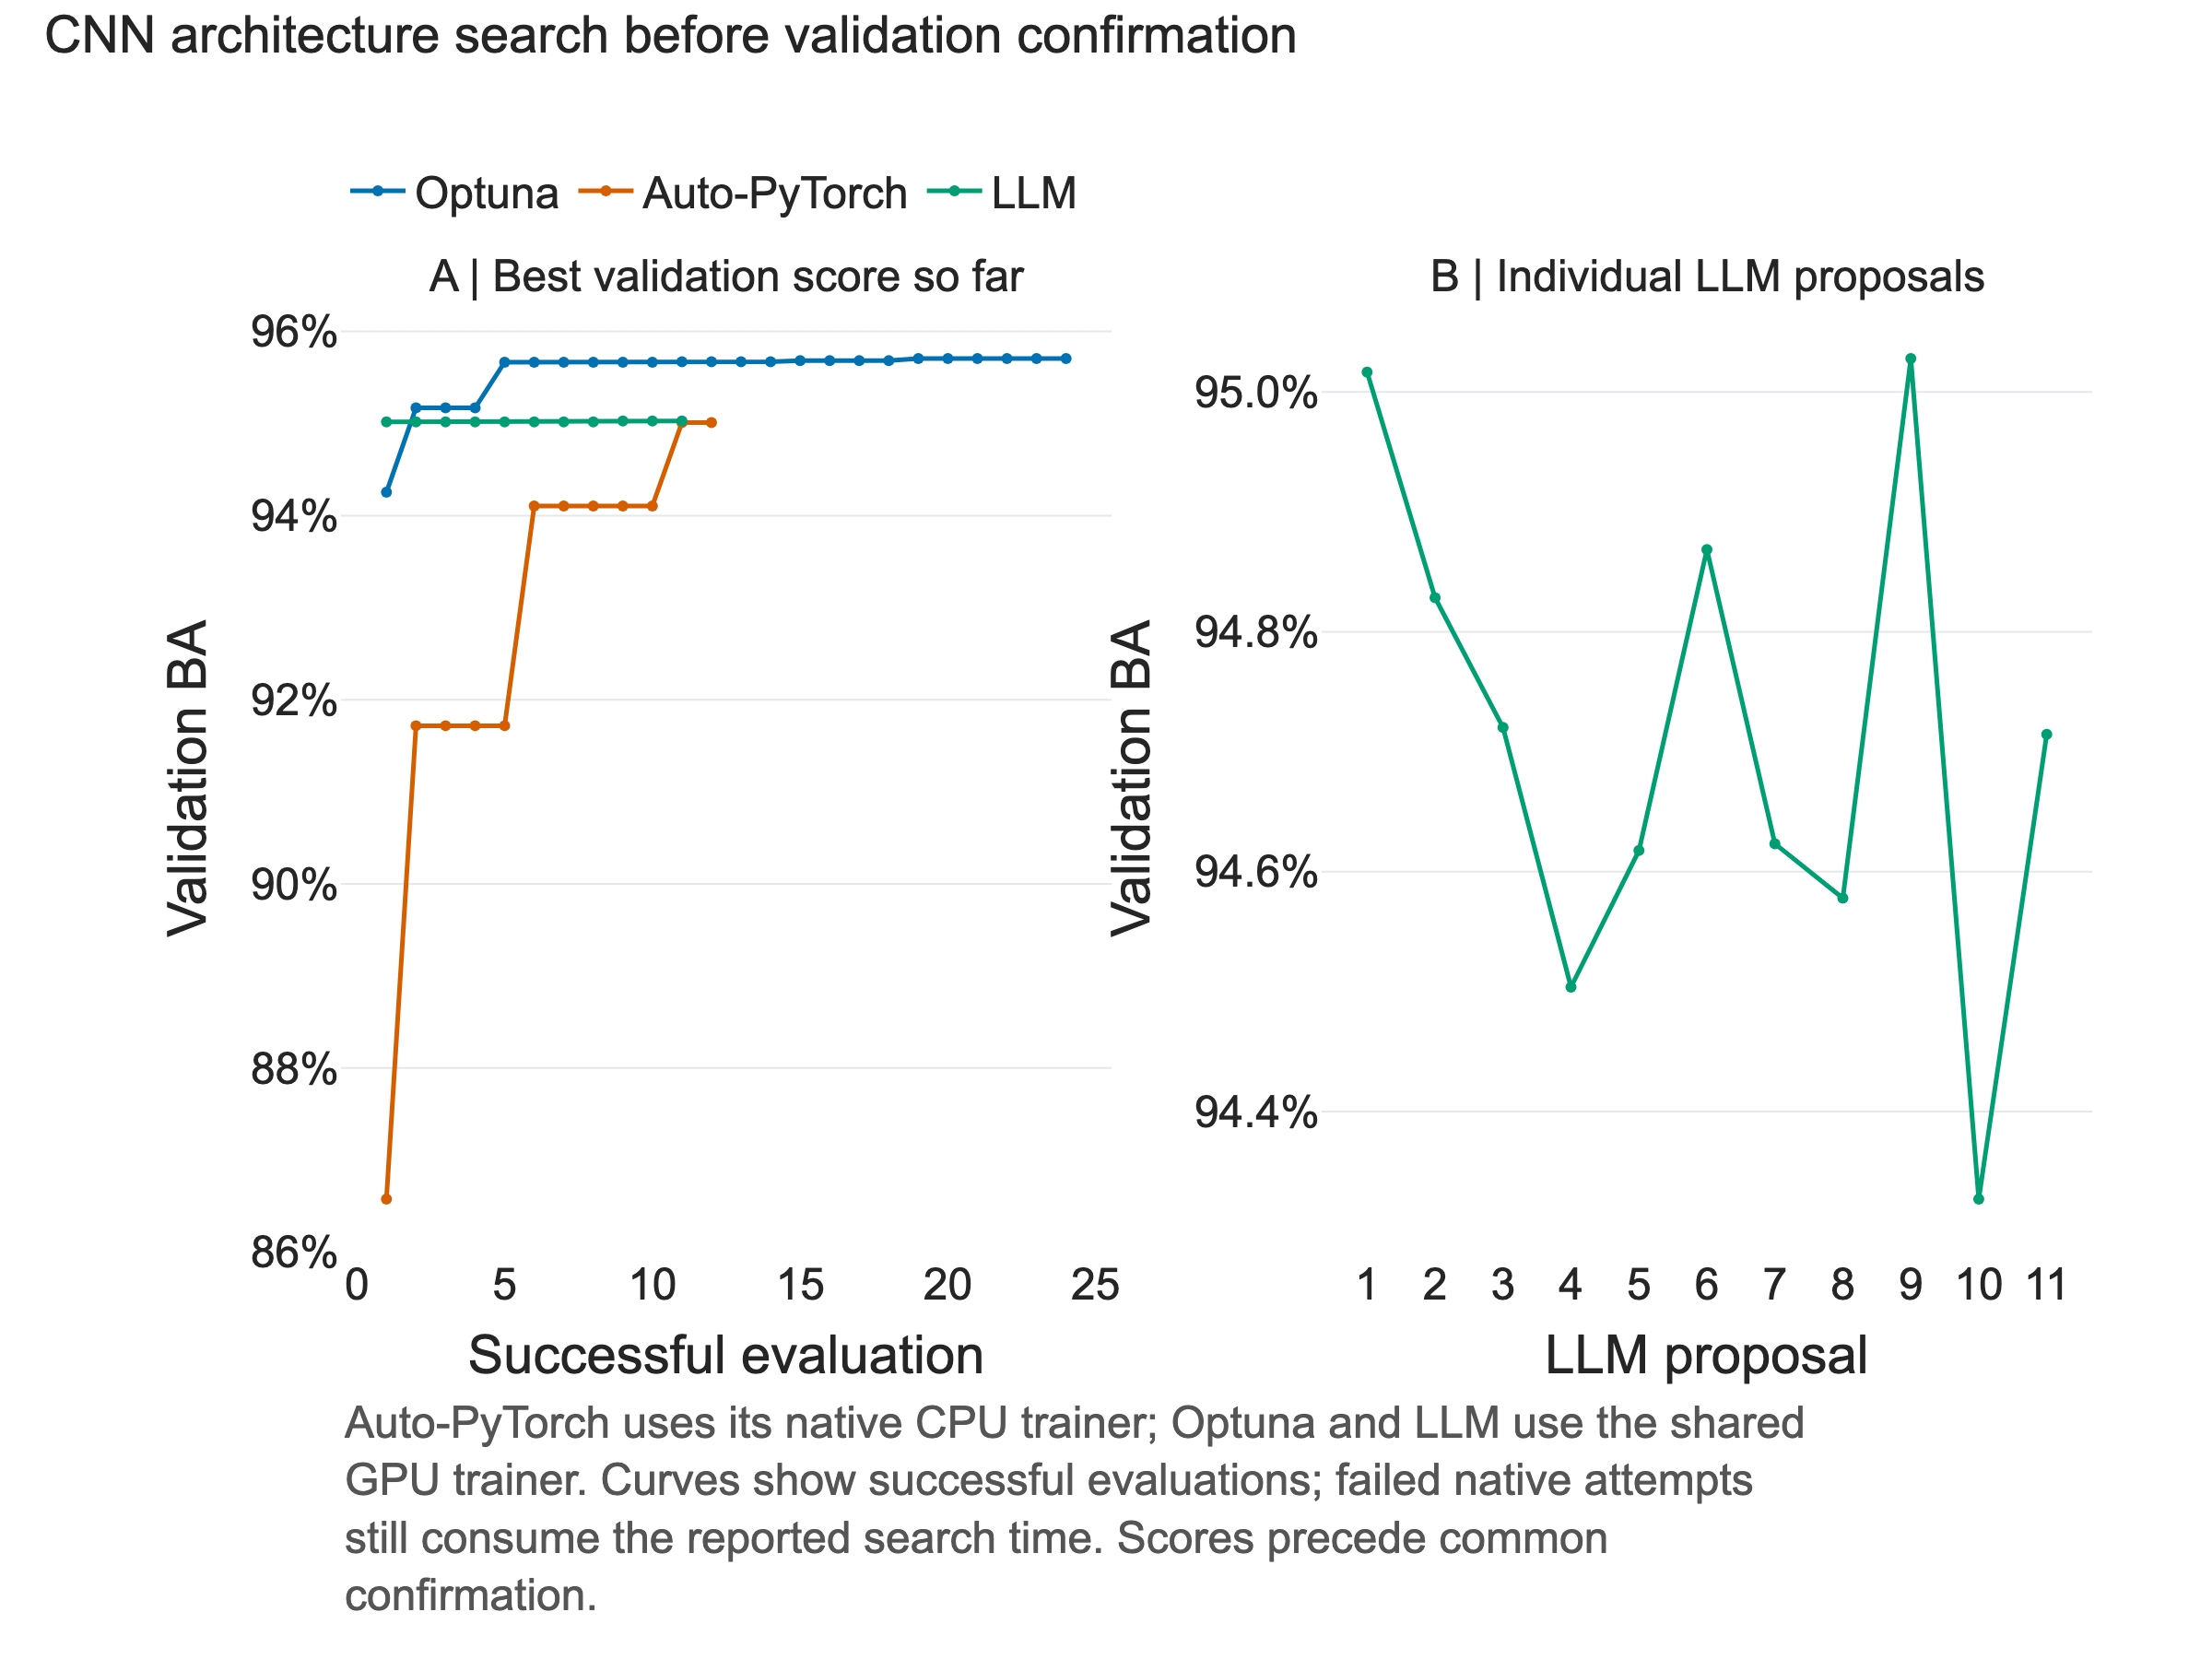

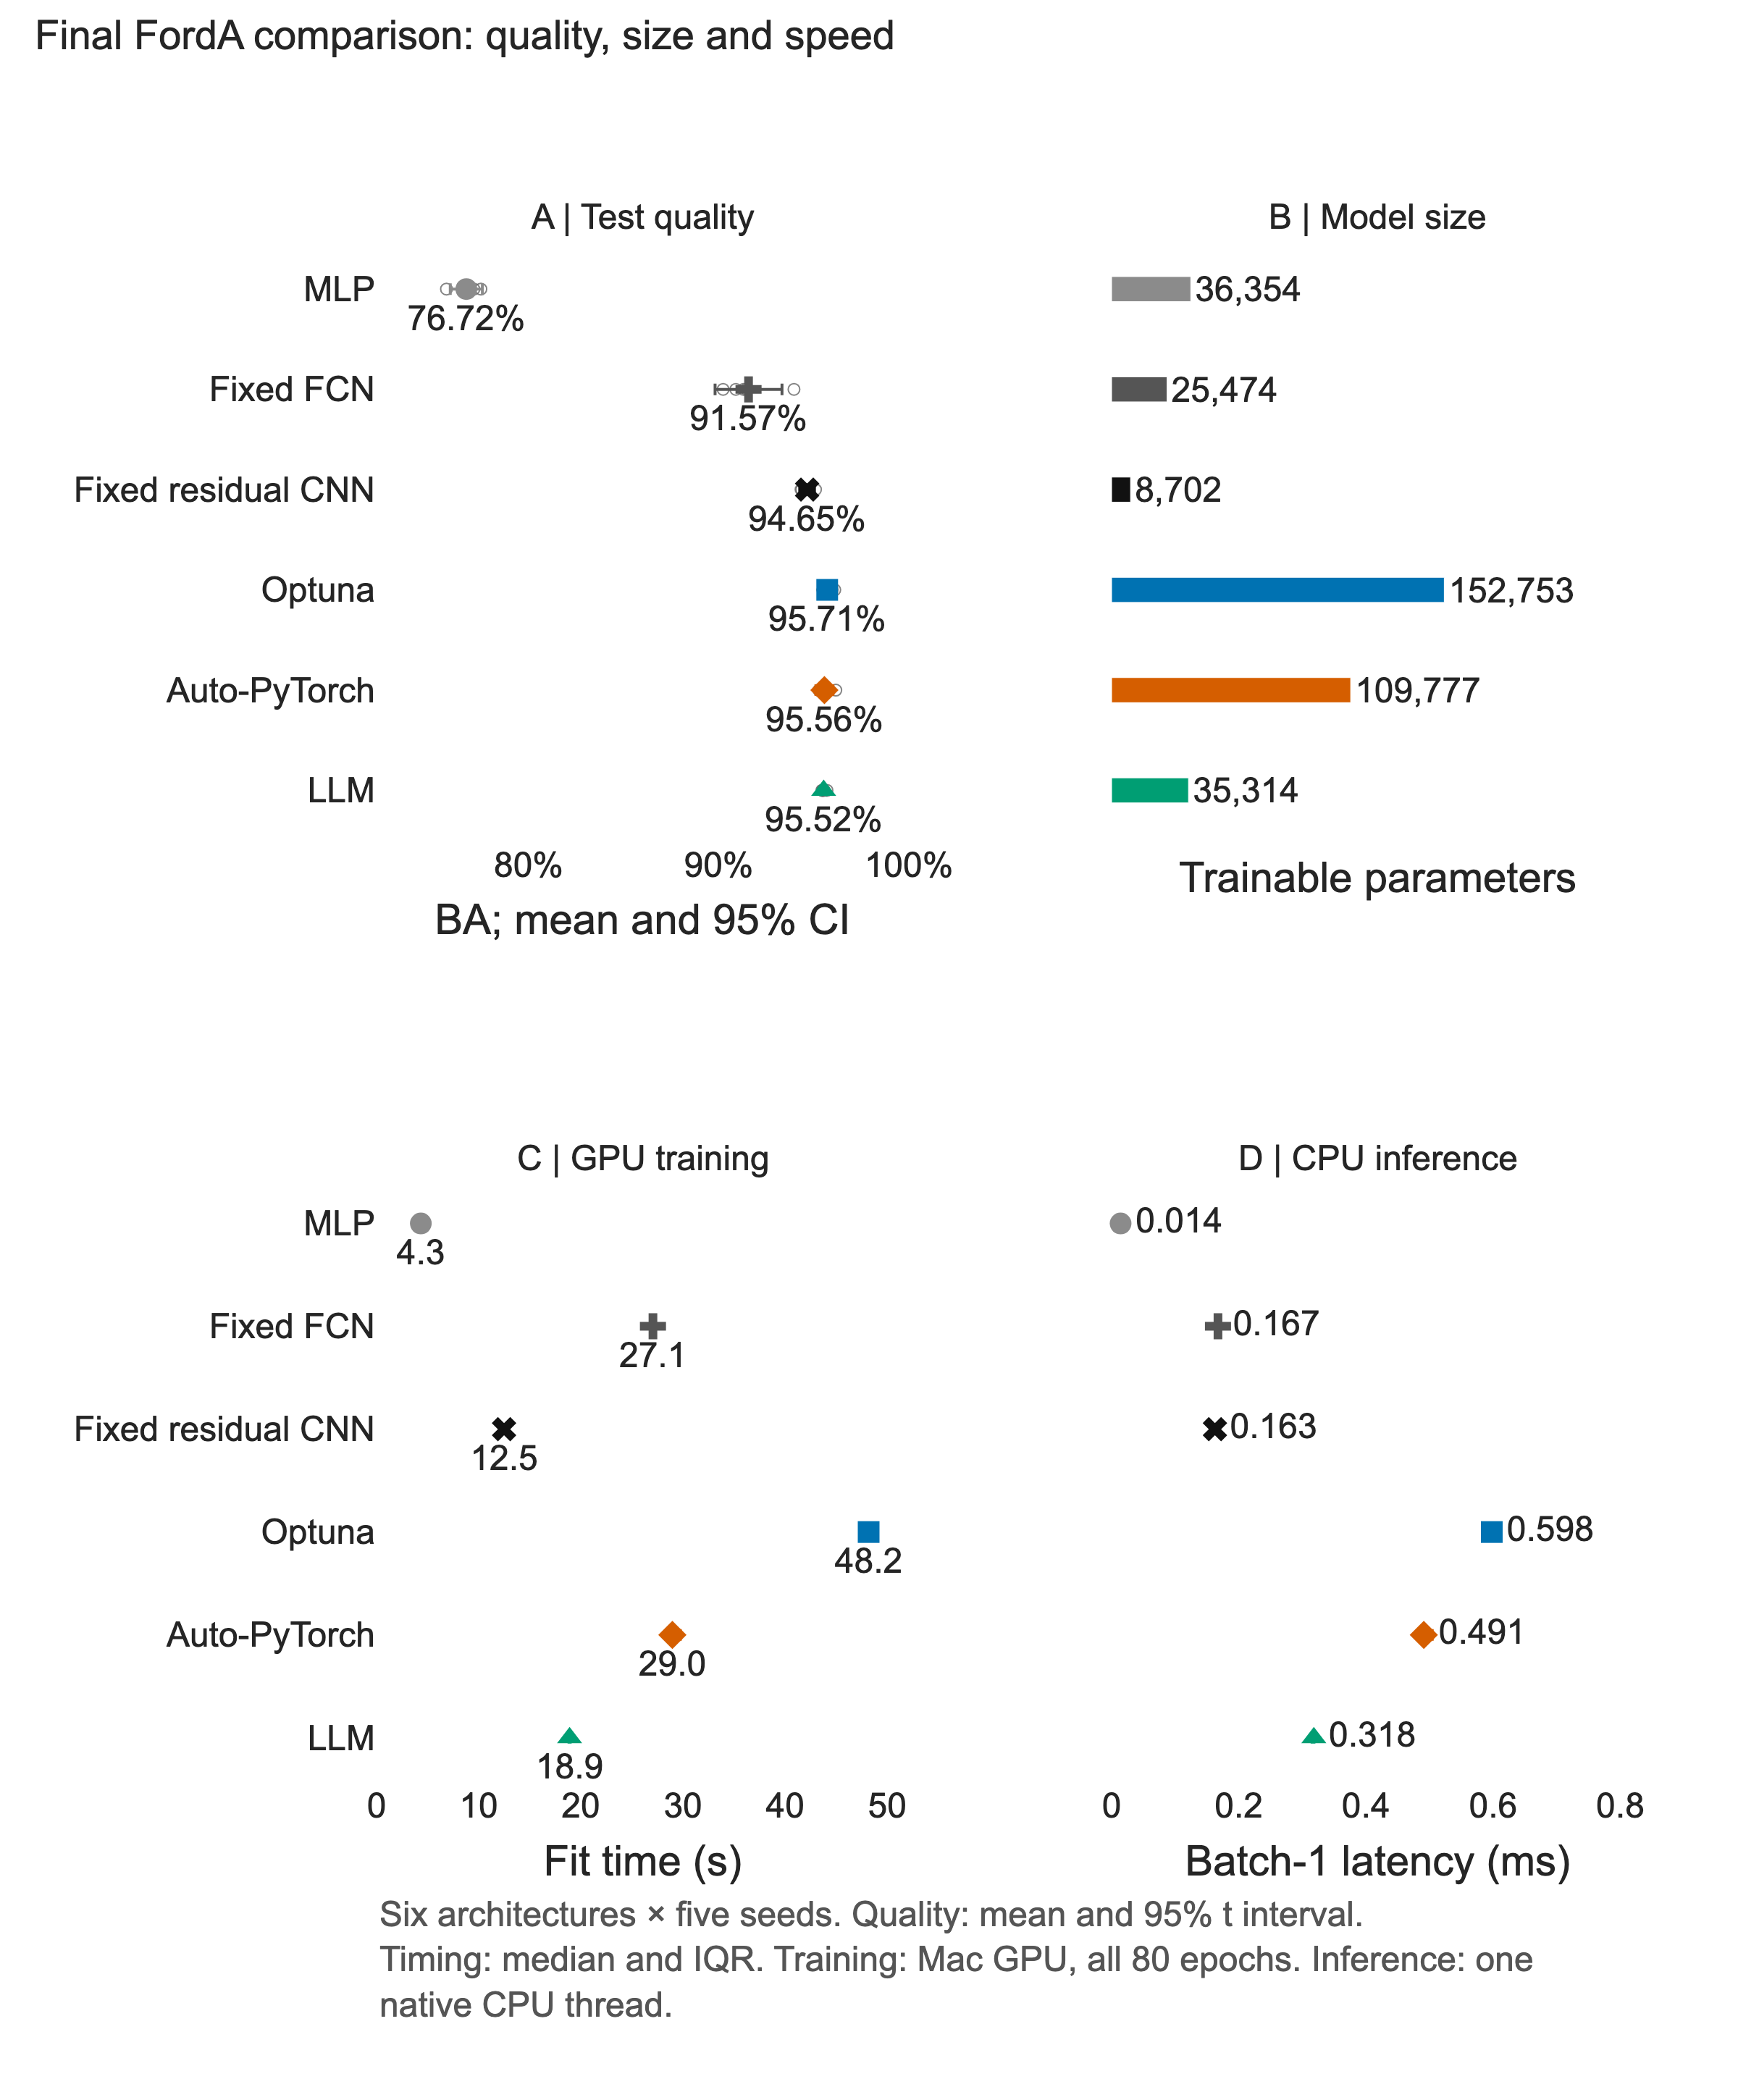

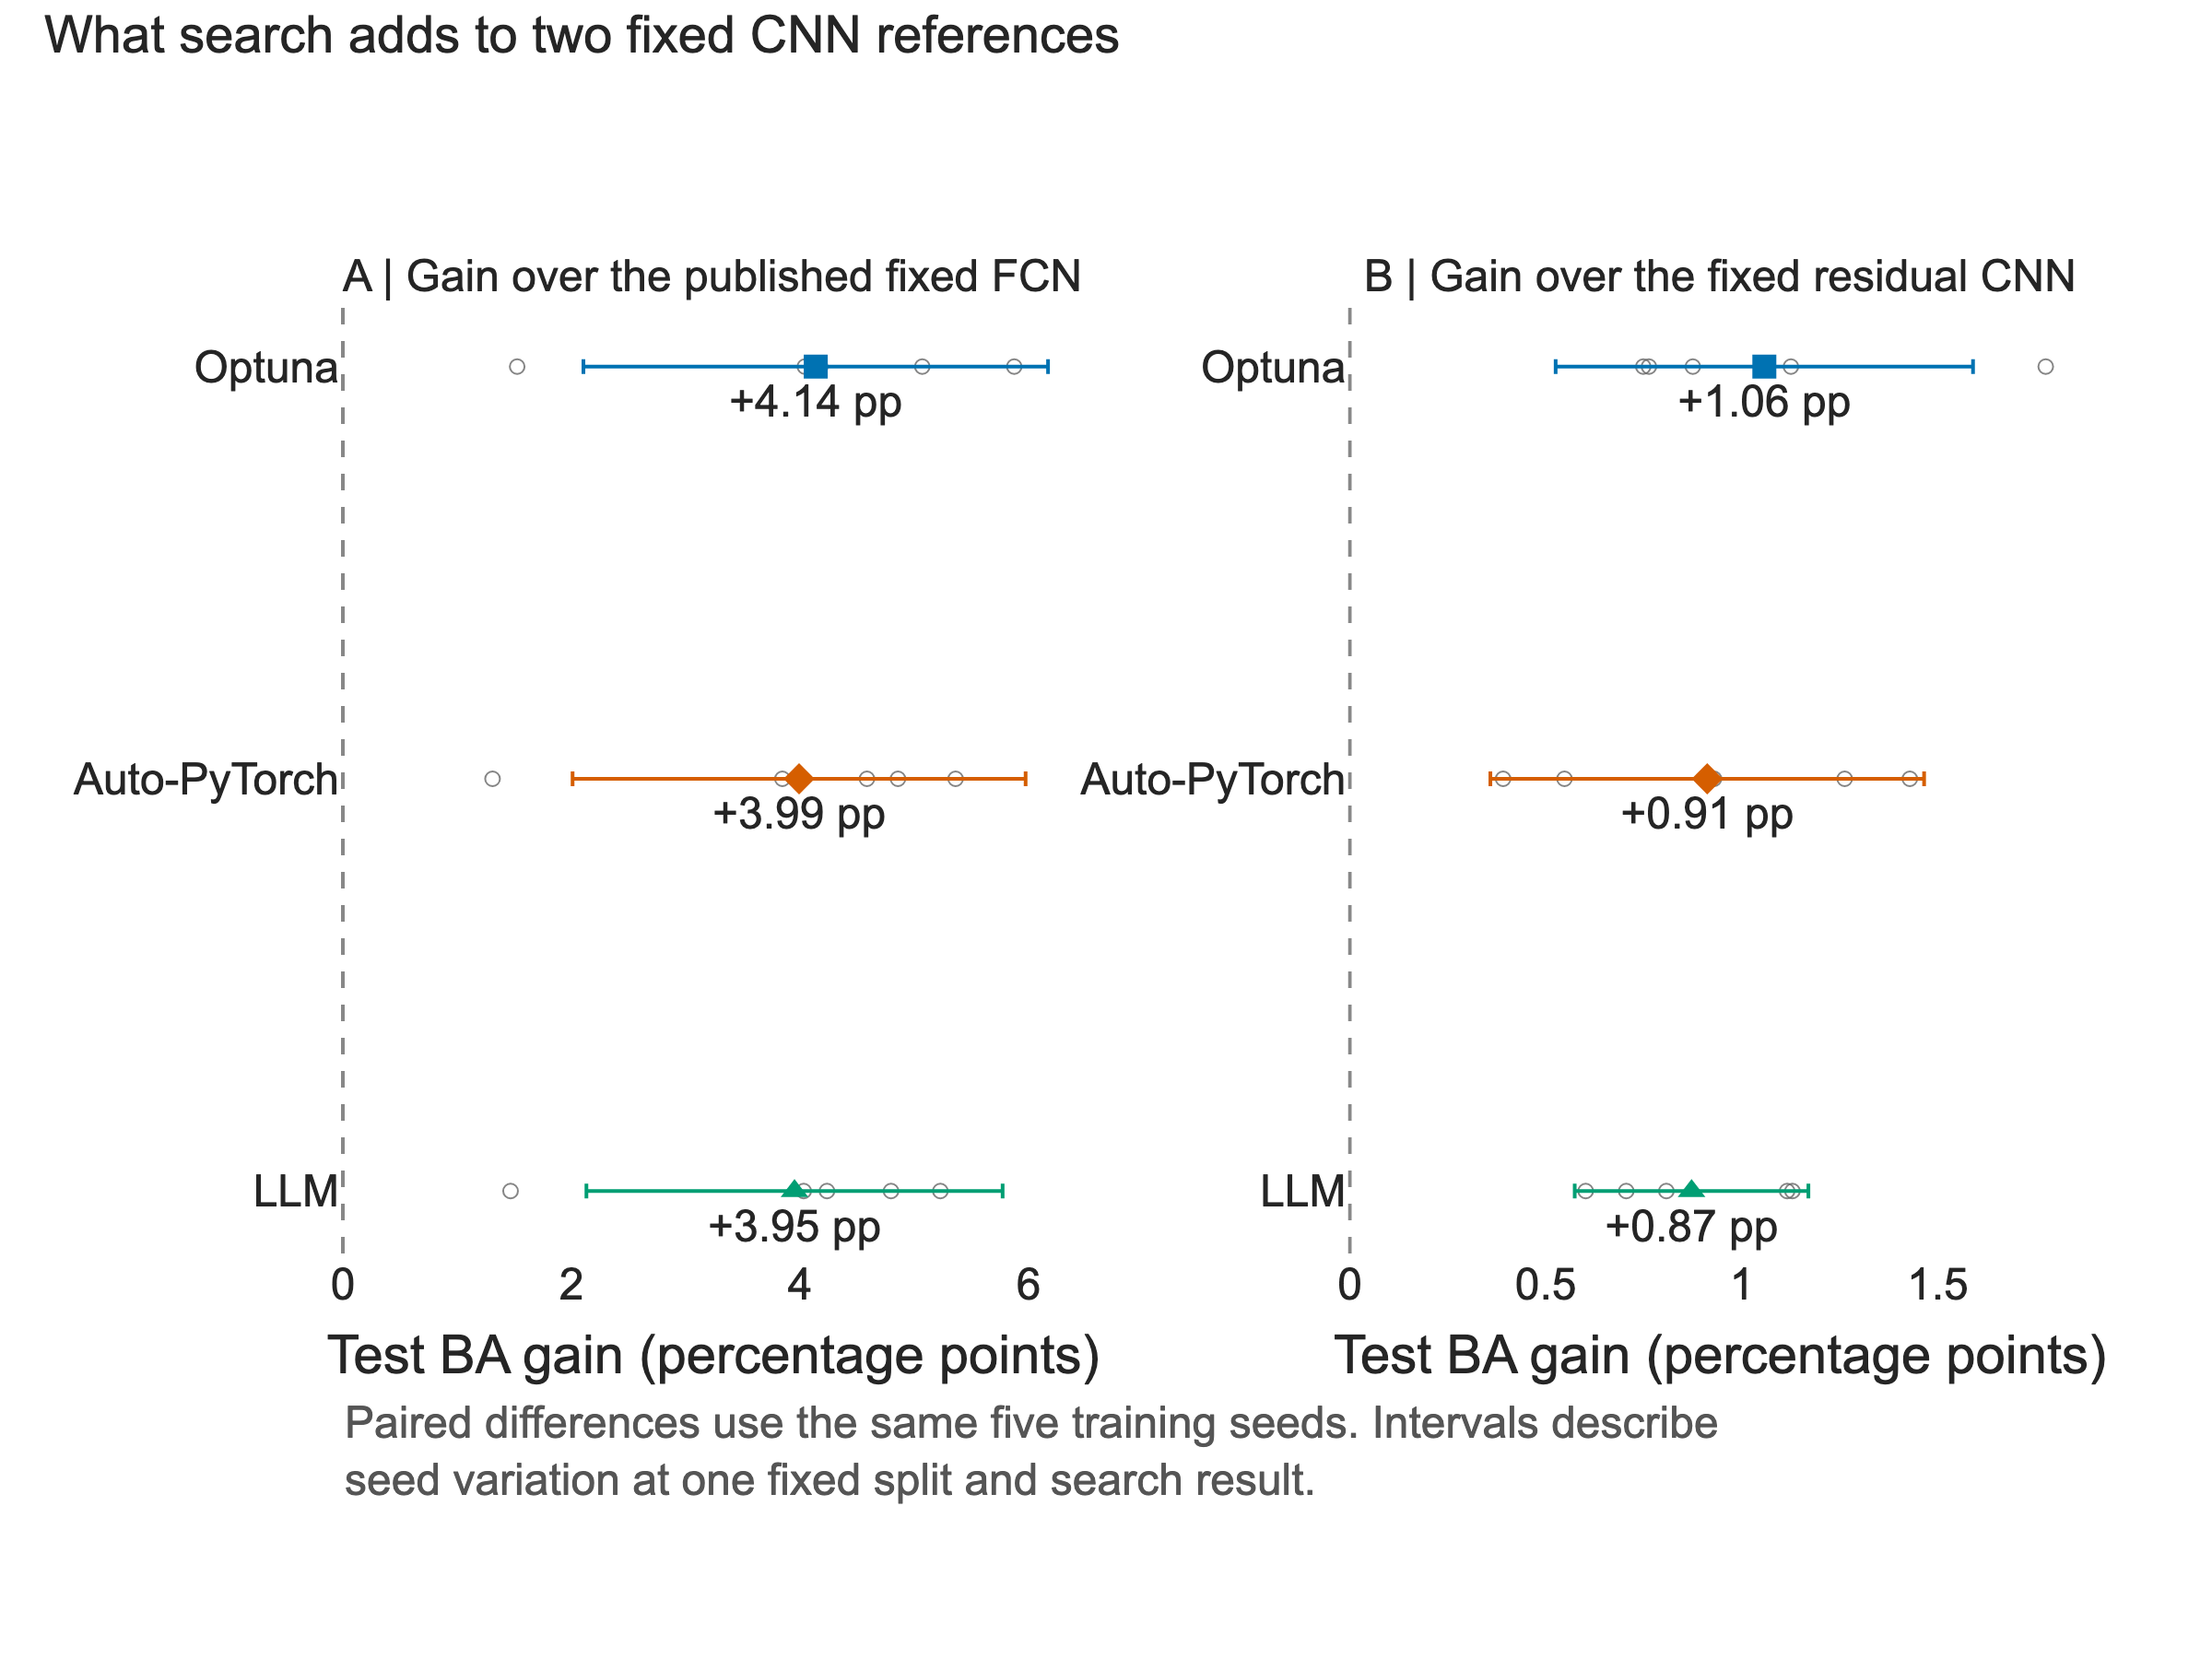

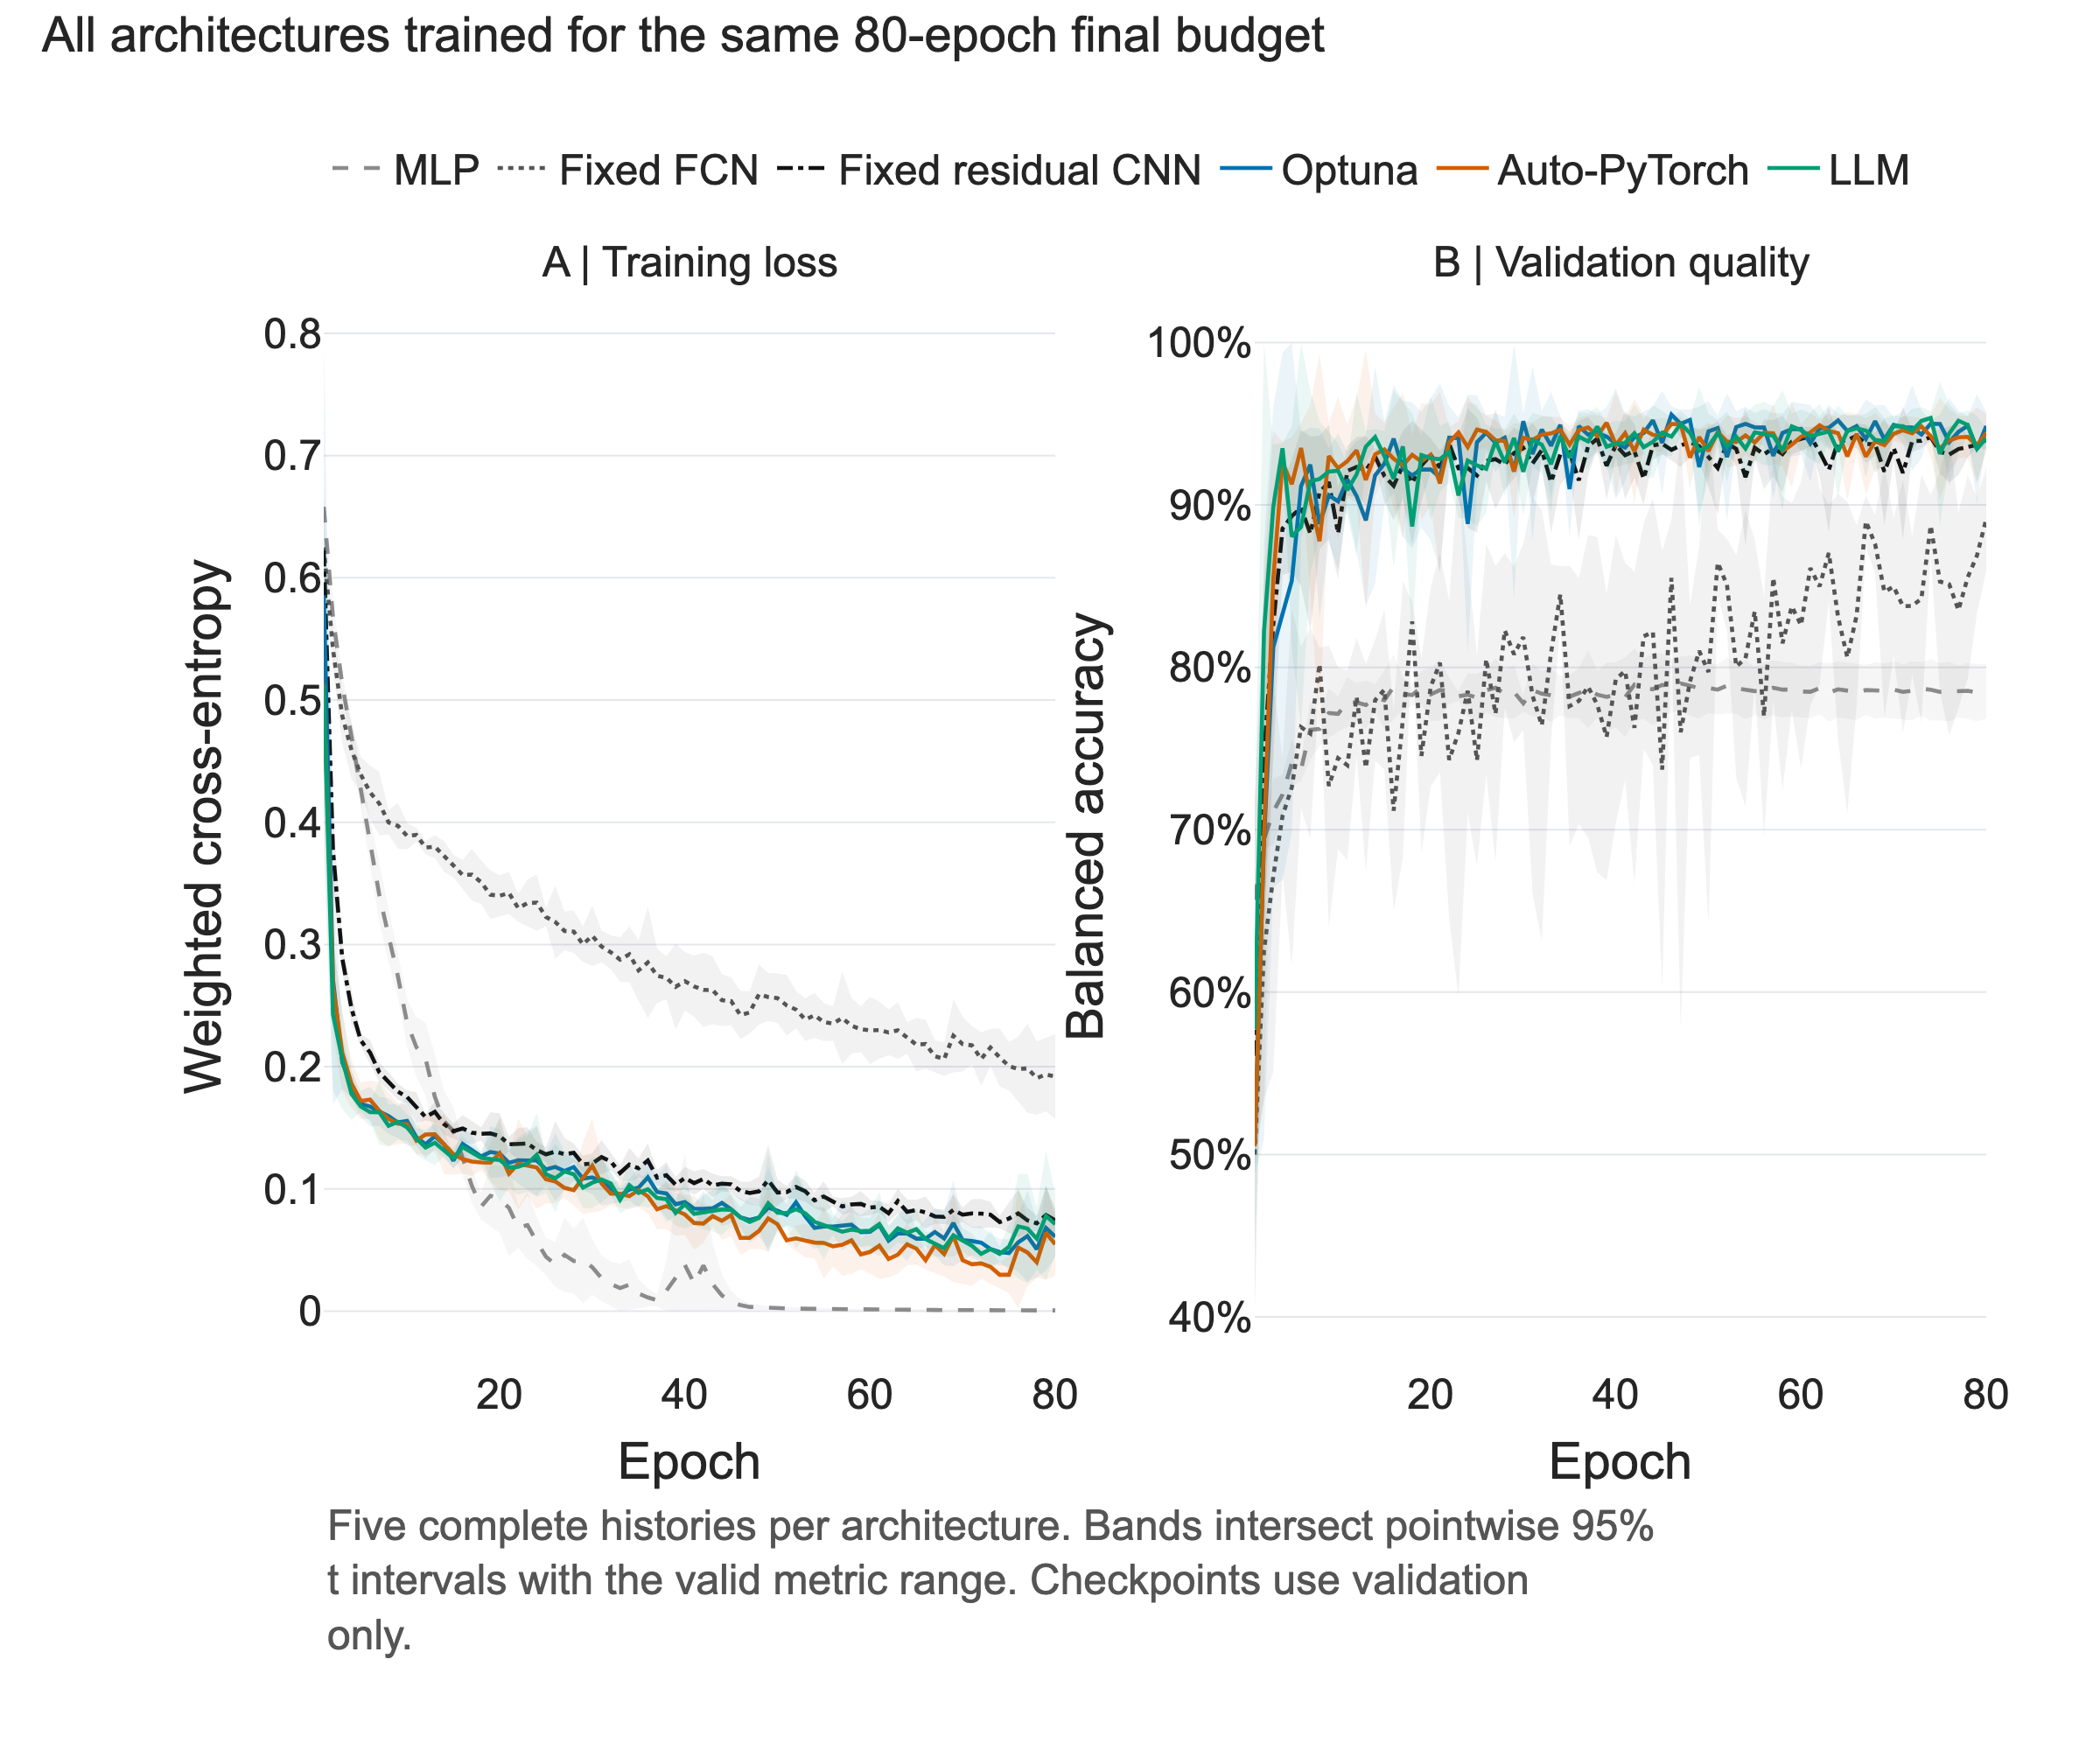

,method,reference,gain_pp,ci_pp
0,Optuna,Fixed FCN,4.137729,2.032731
1,Auto-PyTorch,Fixed FCN,3.992058,1.982000
2,LLM,Fixed FCN,3.952073,1.820850
3,Optuna,Fixed residual CNN,1.057613,0.532416
4,Auto-PyTorch,Fixed residual CNN,0.911943,0.553275
5,LLM,Fixed residual CNN,0.871957,0.298089


**Optuna:** test BA 95.71% ± 0.38 pp; change from the fixed residual CNN +1.06 pp; 152,753 parameters.

**Auto-PyTorch:** test BA 95.56% ± 0.45 pp; change from the fixed residual CNN +0.91 pp; 109,777 parameters.

**LLM:** test BA 95.52% ± 0.13 pp; change from the fixed residual CNN +0.87 pp; 35,314 parameters.

In [21]:
summary = summarize_final(final)
summary.to_csv(RESULTS / "comparison_summary.csv", index=False)
readable = summary.copy()
readable["Test BA, mean ± 95% CI"] = readable.apply(lambda r: f"{100*r.test_ba:.2f}% ± {100*r.ba_ci:.2f} pp", axis=1)
readable["Macro-F1, mean ± 95% CI"] = readable.apply(lambda r: f"{r.macro_f1:.4f} ± {r.f1_ci:.4f}", axis=1)
display(readable[["method",
            "Test BA, mean ± 95% CI",
            "Macro-F1, mean ± 95% CI",
            "parameters",
            "fit_seconds",
            "latency_ms",
            "p95_ms",
            "throughput"]])
architectures = pd.DataFrame([{"method": method,
            "architecture": architecture_description(config),
            "theoretical_receptive_field": receptive_field(config)}
        for method, config in frozen["architectures"].items()])
with pd.option_context("display.max_colwidth", None):
    display(architectures)
search_rows = []
for method, phase in searches.items():
    records = [r for r in phase["records"] if "status" not in r or "SUCCESS" in r["status"]]
    confirmation_fits = [fit for row in confirmation["records"] if row["method"] == method for fit in row["records"]]
    search_rows.append({"method": method,
            "attempted_evaluations": len(phase["records"]),
            "successful_evaluations": len(records),
            "distinct_structures": len({structural_key(r["config"]) for r in records}),
            "stage_counts": str(sorted({len(r["config"]["stages"]) for r in records})),
            "search_wall_seconds": phase["wall_seconds"],
            "confirmation_fits": len(confirmation_fits),
            "confirmation_fit_seconds": sum(r["fit_seconds"] for r in confirmation_fits)})
search_summary = pd.DataFrame(search_rows)
search_summary.to_csv(RESULTS / "search_summary.csv", index=False)
display(search_summary)
export_figure(search_figure(searches),
    "search_progress",
    "Auto-PyTorch uses its native CPU trainer; Optuna and LLM use the shared GPU trainer. Curves show successful evaluations; failed native attempts still consume the reported search time. Scores precede common confirmation.")
export_figure(final_comparison_figure(final, summary),
    "final_comparison",
    "Six architectures × five seeds. Quality: mean and 95% t interval. Timing: median and IQR. Training: Mac GPU, all 80 epochs. Inference: one native CPU thread.",
    width=1200,
    height=1450)
export_figure(paired_gain_figure(final),
    "paired_improvements",
    "Paired differences use the same five training seeds. Intervals describe seed variation at one fixed split and search result.",
    height=900)
export_figure(learning_curve_figure(final),
    "learning_curves",
    "Five complete histories per architecture. Bands intersect pointwise 95% t intervals with the valid metric range. Checkpoints use validation only.",
    height=1000)
gains = pd.read_csv(RESULTS / "paired_improvements.csv")
display(gains)
for method in ["Optuna", "Auto-PyTorch", "LLM"]:
    row = summary.set_index("method").loc[method]
    reference = summary.set_index("method").loc["Fixed residual CNN"]
    display(Markdown(f"**{method}:** test BA {100*row.test_ba:.2f}% ± {100*row.ba_ci:.2f} pp; "
            f"change from the fixed residual CNN {100*(row.test_ba-reference.test_ba):+.2f} pp; {int(row.parameters):,} parameters."))


## Scope of the result

The paired comparisons distinguish the published fixed FCN from the fixed residual CNN in the same search family. A positive mean is an observed gain; an interval that includes zero does not establish a consistently positive seed-averaged difference under this protocol. These comparisons are descriptive and are not adjusted for multiple testing.

The 45-minute native search produced 20 logged records: 12 successful evaluations, six timeouts, one running record and one stop record. Only successful records enter the shortlist. Common confirmation and final training are separate from the library's original native scores.

Theoretical receptive fields are measured before global pooling and can exceed 500 because of padding; real signal support is bounded by the 500-sample input. The official test was also evaluated in earlier lab revisions. Current choices use development data only, but the revision history is not a prospectively untouched benchmark.

Sources: [FordA and the FCN architecture](https://keras.io/examples/timeseries/timeseries_classification_from_scratch/), [Auto-PyTorch](https://github.com/automl/Auto-PyTorch), [Optuna numerical spaces](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/002_configurations.html).

## 11. LLM architecture evolution

The table reports all eleven proposals, validation metrics and changes from the preceding architecture. The static diagram shows the stem, residual stages and pooled classifier; changed stages are highlighted.

Search metrics describe single 20-epoch fits on validation data. The frozen winner comes from separate two-seed, 40-epoch confirmation and can differ from the best search checkpoint. Stages are aligned by position; the comparison does not infer architecture ancestry.


In [22]:
from html import escape
from IPython.display import SVG


def architecture_changes(previous, current):
    changes = []
    if previous["stem_width"] != current["stem_width"]:
        changes.append(f"stem {previous['stem_width']} → {current['stem_width']}")
    if len(previous["stages"]) != len(current["stages"]):
        changes.append(f"stages {len(previous['stages'])} → {len(current['stages'])}")
    for i in range(max(len(previous["stages"]), len(current["stages"]))):
        old = previous["stages"][i] if i < len(previous["stages"]) else None
        new = current["stages"][i] if i < len(current["stages"]) else None
        if old is None or new is None:
            changes.append(f"stage {i + 1} {('added' if old is None else 'removed')}")
        else:
            for key in ["width", "blocks", "kernel_size", "dropout", "activation", "block_type", "pooling"]:
                if old[key] != new[key]:
                    changes.append(f"S{i + 1} {key}: {old[key]} → {new[key]}")
    return "; ".join(changes) or "No changes"


def proposal_summary(records, frozen_config):
    rows = []
    for i, record in enumerate(records):
        previous = records[i - 1] if i else None
        rows.append({"proposal": record["iteration"],
                "frozen": record["config"] == frozen_config,
                "validation_BA_pct": 100 * record["val_ba"],
                "BA_delta_vs_previous_pp": 100 * (record["val_ba"] - previous["val_ba"]) if previous else None,
                "checkpoint_validation_loss": record["val_loss"],
                "last_train_loss": record["history"][-1]["train_loss"],
                "last_validation_loss": record["history"][-1]["val_loss"],
                "parameters": record["parameters"],
                "best_epoch": record["best_epoch"],
                "fit_seconds": record["fit_seconds"],
                "changes_vs_previous": (architecture_changes(previous["config"], record["config"]) if previous else "Initial proposal")})
    return pd.DataFrame(rows)


def proposal_architecture_svg(records, frozen_config):
    width, row_height = (1460, 160)
    height = 86 + len(records) * row_height
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-labelledby="gallery-title gallery-desc">',
        '<title id="gallery-title">All eleven LLM CNN proposals</title>',
        '<desc id="gallery-desc">Each row shows the stem, residual stages and pooled classifier. Cyan boxes changed from the preceding proposal. Stage labels give channels, blocks, kernel and dropout.</desc>',
        '<rect width="100%" height="100%" fill="white"/>',
        '<g font-family="Arial,sans-serif" font-size="16" font-weight="500" fill="#20262c">',
        '<text x="16" y="28" font-size="24">LLM architecture evolution on FordA</text>',
        '<text x="16" y="58">Cyan: changed from the previous proposal · read left to right · stage operation labels show activation, connectivity and pooling</text>']
    for i, r in enumerate(records):
        y = 86 + i * row_height
        config = r["config"]
        prior = records[i - 1]["config"] if i else None
        svg.append(f"""<text x="16" y="{y + 22}" font-weight="700">Proposal {r['iteration']}</text>""")
        svg.append(f"""<text x="16" y="{y + 48}">{100 * r['val_ba']:.2f}% BA</text>""")
        if config == frozen_config:
            svg.append(f'<text x="16" y="{y + 76}" fill="#005c75">Frozen</text>')
        boxes = [("Stem",
                f"{config['stem_width']} channels",
                "k7 · stride 2",
                "length 250",
                prior is not None and config["stem_width"] != prior["stem_width"])]
        length = 250
        for j in range(4):
            if j < len(config["stages"]):
                s = config["stages"][j]
                length //= 2
                changed = prior is not None and (j >= len(prior["stages"]) or s != prior["stages"][j])
                boxes.append((f"Stage {j + 1}",
                        f"{s['width']} ch · {s['blocks']} blocks",
                        f"k{s['kernel_size']} p{s['dropout']:g} {s['activation']}",
                        f"{s['block_type']} · {s['pooling']} · L{length}",
                        changed))
            else:
                boxes.append((f"Stage {j + 1}", "Absent", "", "", prior is not None and j < len(prior["stages"])))
        boxes.append(("Mean ⊕ max", f"{2 * config['stages'][-1]['width']} features", "Linear → 2 logits", "", False))
        for j, (title, line1, line2, line3, changed) in enumerate(boxes):
            x = 140 + j * 215
            fill, stroke = ("#dff4fa", "#005c75") if changed else ("#f5f7f8", "#8d9da5")
            svg.append(f'<rect x="{x}" y="{y}" width="205" height="104" rx="4" fill="{fill}" stroke="{stroke}"/>')
            for dy, text in [(22, title), (46, line1), (69, line2), (92, line3)]:
                svg.append(f'<text x="{x + 8}" y="{y + dy}">{escape(text)}</text>')
            if j < 5:
                svg.append(f'<path d="M{x + 205} {y + 52} h10 m-4 -4 l4 4 -4 4" fill="none" stroke="#424b50"/>')
    return "".join(svg) + "</g></svg>"


### All proposals: architecture changes and recorded metrics

,proposal,Val BA (%),Δ previous (pp),Val loss,parameters,Best epoch,Fit (s),frozen
0,1,95.0165,NaN,0.1345,35314,16,5.3719,True
1,2,94.8284,-0.1881,0.1455,29950,17,5.4011,False
2,3,94.7201,-0.1082,0.1484,44722,12,6.5731,False
3,4,94.5037,-0.2164,0.1542,49874,13,6.6651,False
4,5,94.6176,0.1139,0.1465,50210,8,6.3509,False
5,6,94.8686,0.2510,0.1435,35314,19,4.7089,False
6,7,94.6233,-0.2453,0.1528,35314,17,4.8979,False
7,8,94.5779,-0.0454,0.1411,29874,17,5.0542,False
8,9,95.0278,0.4499,0.1384,34930,18,4.5922,False
9,10,94.3269,-0.7009,0.1684,37650,11,4.6764,False


,proposal,changes_vs_previous
0,1,Initial proposal
1,2,stem 16 → 12; stages 2 → 3; S1 width: 16 → 12;...
2,3,stem 12 → 16; stages 3 → 4; S1 width: 12 → 16;...
3,4,stages 4 → 1; S1 width: 16 → 24; S1 blocks: 2 ...
4,5,stages 1 → 2; S1 width: 24 → 20; S1 blocks: 3 ...
5,6,S1 width: 20 → 16; S1 block_type: plain → resi...
6,7,S1 block_type: residual → plain; S2 pooling: m...
7,8,S2 width: 24 → 20; S2 pooling: avg → max
8,9,S2 width: 20 → 24; S2 block_type: residual → p...
9,10,S1 blocks: 2 → 1; S2 blocks: 2 → 3


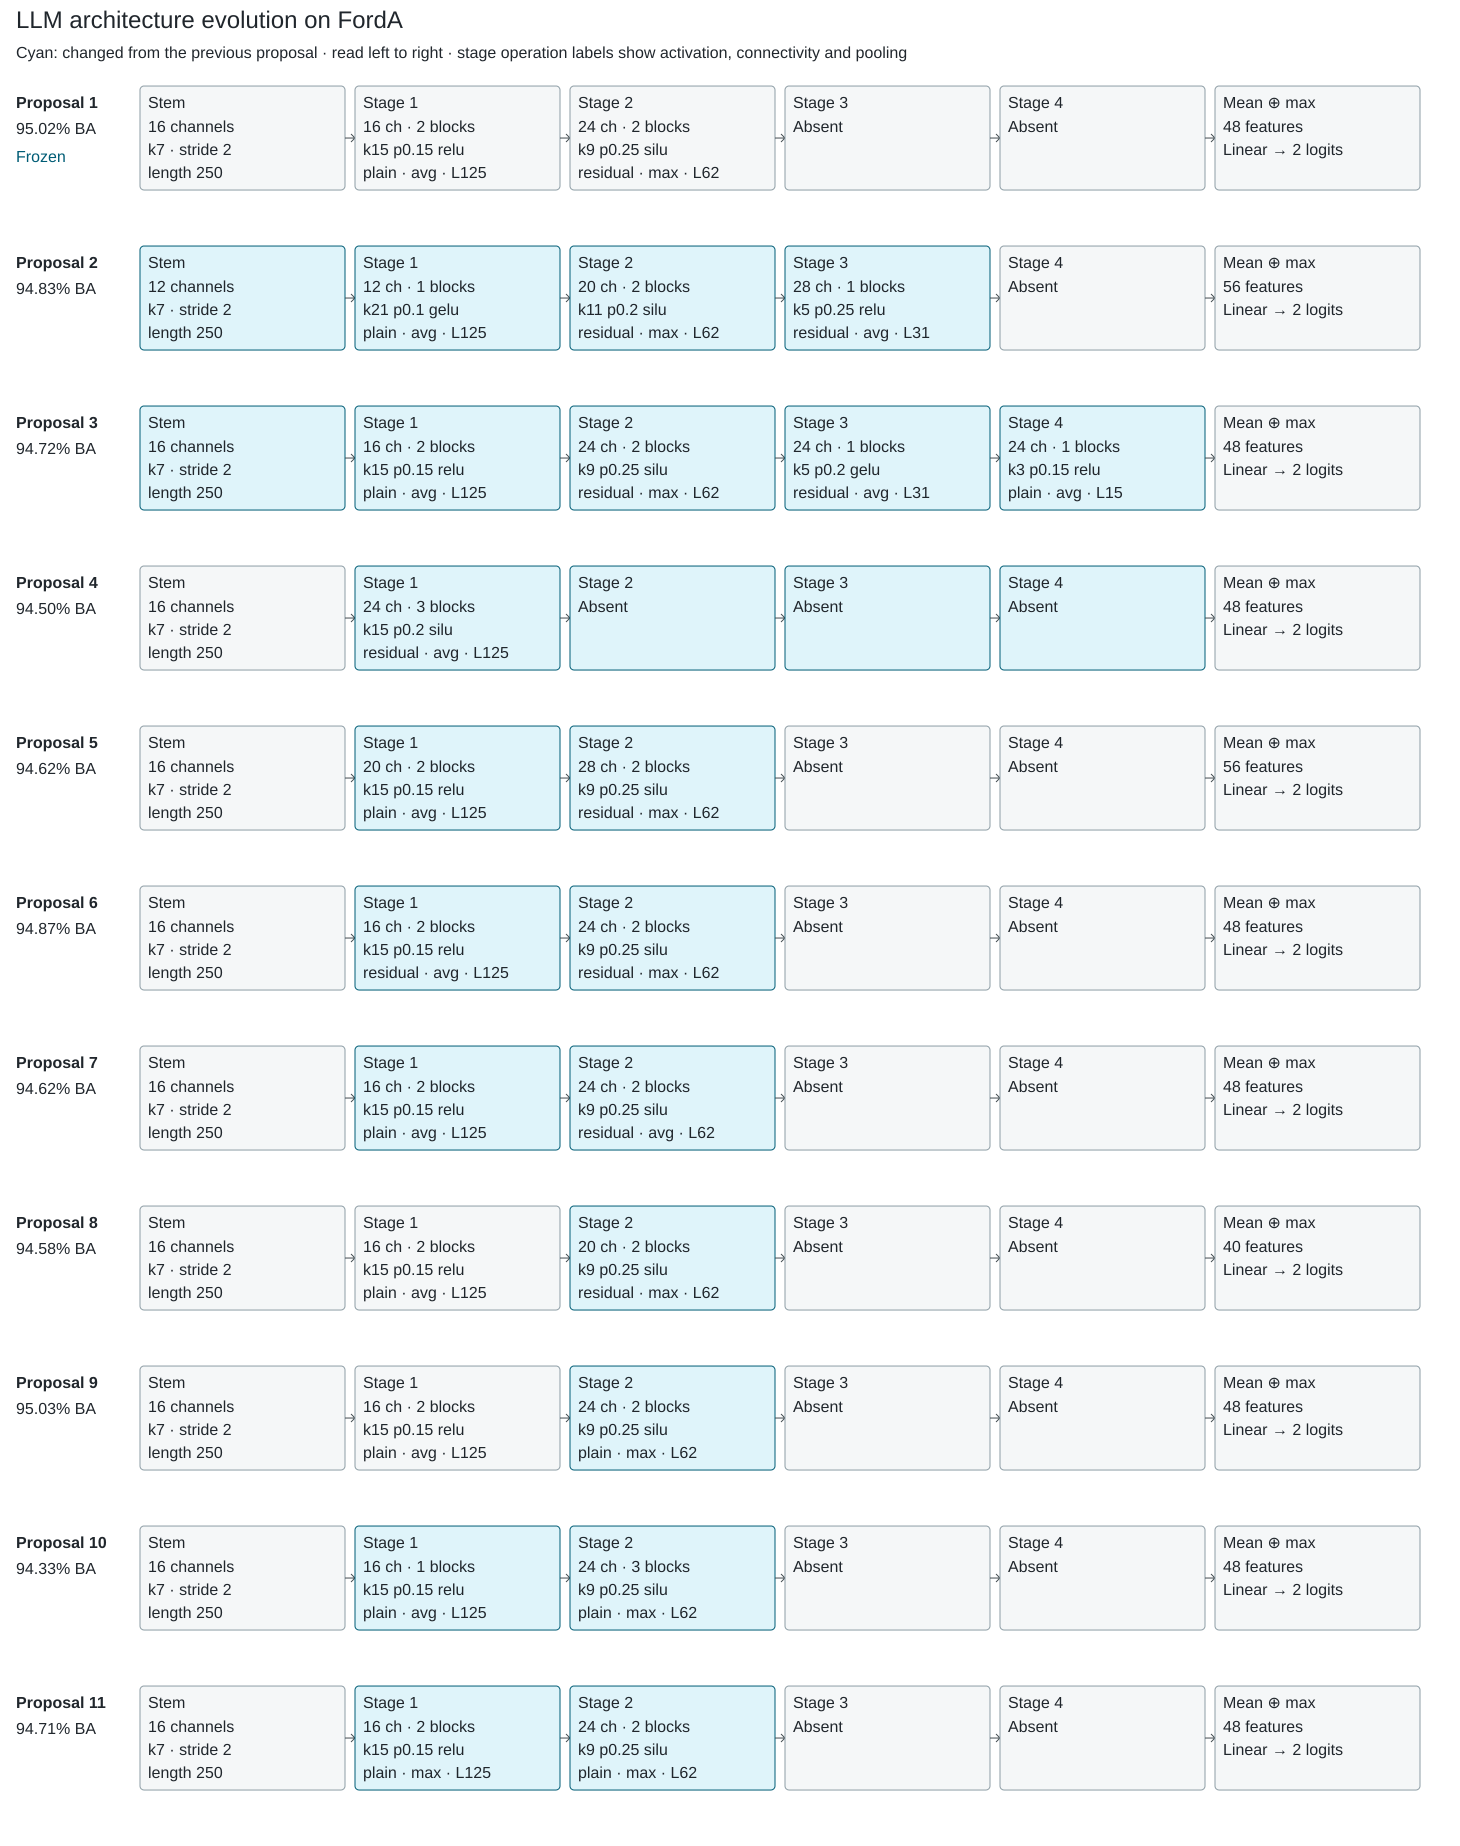

In [23]:
llm_records = searches["LLM"]["records"]
llm_table = proposal_summary(llm_records, frozen["architectures"]["LLM"])
llm_table.to_csv(RESULTS / "llm_proposal_summary.csv", index=False)
display(Markdown("### All proposals: architecture changes and recorded metrics"))
with pd.option_context("display.max_colwidth", None, "display.precision", 4):
    display(llm_table[["proposal",
                "validation_BA_pct",
                "BA_delta_vs_previous_pp",
                "checkpoint_validation_loss",
                "parameters",
                "best_epoch",
                "fit_seconds",
                "frozen"]].rename(columns={"validation_BA_pct": "Val BA (%)",
                "BA_delta_vs_previous_pp": "Δ previous (pp)",
                "checkpoint_validation_loss": "Val loss",
                "best_epoch": "Best epoch",
                "fit_seconds": "Fit (s)"}))
display(llm_table[["proposal", "changes_vs_previous"]])
llm_gallery = proposal_architecture_svg(llm_records, frozen["architectures"]["LLM"])
(LAB / "figures/forda_cnn_nas/llm_architecture_evolution.svg").write_text(llm_gallery)
display(SVG(data=llm_gallery))


## 12. Architecture operation checks

The saved traced graphs must contain the selected activation and pooling operations, with residual additions only where requested. These checks verify the executed architecture choices rather than only their configuration labels.

In [24]:
from collections import Counter

operation_checks = []
for method, phase in searches.items():
    records = [r for r in phase["records"] if "status" not in r or "SUCCESS" in r["status"]]
    for record in records:
        stages = record["config"]["stages"]
        modules = Counter(node.get("module_type") for node in record["architecture_graph"]["nodes"])
        for name, module_type in [("relu", "ReLU"), ("gelu", "GELU"), ("silu", "SiLU")]:
            assert modules[module_type] == (1 if name == "relu" else 0) + 2 * sum(s["blocks"] for s in stages if s["activation"] == name)
        assert modules["AvgPool1d"] == sum(s["pooling"] == "avg" for s in stages)
        assert modules["MaxPool1d"] == sum(s["pooling"] == "max" for s in stages)
    operation_checks.append({"method": method, "graphs_checked": len(records), "stage_counts": sorted({len(r["config"]["stages"]) for r in records}), **{name: sorted({s[name] for r in records for s in r["config"]["stages"]}) for name in ["activation", "block_type", "pooling"]}})
write_json(RESULTS / "operation_graph_verification.json", {"successful": True, "records": operation_checks})
display(pd.DataFrame(operation_checks))


,method,graphs_checked,stage_counts,activation,block_type,pooling
0,Optuna,24,"[1, 2, 3, 4]","[gelu, relu, silu]","[plain, residual]","[avg, max]"
1,Auto-PyTorch,12,"[1, 2, 3, 4]","[gelu, relu, silu]","[plain, residual]","[avg, max]"
2,LLM,11,"[1, 2, 3, 4]","[gelu, relu, silu]","[plain, residual]","[avg, max]"
